
### LECTURE8: 차원축소와 segmentation

### 실습:: *tSNE, Umap, AutoEncoder, Variational AutoEncoder*


* 1교시 : 차원에 대해서: tSNE, kNN, Umap
* 2교시 : autoencoder + tied-autoencoder
* 3교시 : variational autoencoder
* 4교시 : FCN, Unet
* 5교시 : Mask R-CNN -> SAM


## 차원에 대해서

특성(feature)은 많으면 많을수록 좋을까?

당연히 너무 적은 것 보다는 다양한 데이터의 측면을 나타내므로 특성이 많은 것이 좋다. 하지만 너무 많으면?

우리가 사용하게 될 러닝 문제에서 trainin set의 feature는 수백개에서 수만개까지 가지고 있는 경우가 있다.

이렇게 많은 feature를 가지고 있는 경우 훈련을 느리게 만들고 더 좋은 솔루션을 찾는 것을 방해한다.

![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdrGHoh%2FbtqVSu7nT1W%2FOvEULafM3kC7p3gzbfnQ81%2Fimg.png)

차원의 저주. 우리는 4차원 이상을 직관적으로 상상하기 힘들다.

![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FboSJYB%2FbtraVTqkwC1%2FSyMcbBfsrOozbaoeKQ4ilK%2Fimg.png)

2차원에서의 데이터 간의 거리 <<<< 고차원에서의 데이터 간의 거리

따라서 고차원에서 Overfitting의 위험이 높다


### 차원의 저주
차원의 저주 knn (k-nearest neighbor)으로 이해해보자
![](https://blog.kakaocdn.net/dn/LDQRC/btrhfxVs54I/rVkQlscpQlMsXLlgG55Qk0/img.png)

먼저 사이킷런(sklearn)에서 knn 분류 모델을 가져오자

In [1]:
from sklearn.neighbors import KNeighborsClassifier

데이터 셋은 사이킷런 데이터셋의 유방암 데이터를 사용해보자

총 30개의 속성과 malignant(악성), benign(양성) 의 두가지 타겟값을 가지고 있다

In [2]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
df_data = pd.DataFrame(data.data)
df_labels = pd.DataFrame(data.target)
df_data.head()

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


데이터 개수가 적을 때 차원(feature)의 크기에 따라 데이터 간의 거리가 멀어지므로 데이터 개수를 줄여서 학습시켜 보자

In [3]:
df_data = df_data.iloc[:100,:]
df_labels = df_labels.iloc[:100]

데이터 feature의 데이터 스케일이 모두 다르므로 모든 피처들을 평균이 0, 분산이 1인 정규분포를 갖도록 만들어준다

hd는 high dimension / ld는 low dimension으로 설정해보자

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df_data, df_labels, test_size=0.4, random_state=42)

scaler = StandardScaler()
scaler.fit(X_train)
X_train_hd = scaler.transform(X_train)
X_test_hd = scaler.transform(X_test)

X_train_ld = X_train_hd[:,:10]
X_test_ld = X_test_hd[:,:10]

In [5]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_ld, y_train)

print(knn.score(X_test_ld, y_test))

0.925


c:\code\.venv\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_hd, y_train)

print(knn.score(X_test_hd, y_test))

0.925


c:\code\.venv\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


높은 차원이 되었는데 정확도가 감소하였다!

물론 모든 경우에 그렇지는 않으나 feature의 개수가 무의미하게 많을 때 특히 이렇게 차원의 저주에 걸리기 쉽다

### 매니폴드(Manifold)

: 모든 데이터를 최대한 오차 없이 잘 아우를 수 있는 subspace (부분 공간)를 의미

![](https://velog.velcdn.com/images%2Fxuio%2Fpost%2Febfccc83-3168-4956-af90-3df89c9f1fbb%2Fimage.png)



**Manifold Learning**은 이러한 manifold를 잘 찾는 것을 목표로 하는 학습

고차원의 manifold를 잘 찾아낸다면, 고차원의 manifold를 저차원으로 압축했을 때 각 데이터들의 특징을 유지하면서 압축이 가능

![](https://lh3.googleusercontent.com/fife/AMPSemf28lYyrKwgkwasITqBj7ZQ07p9ugPibp-pHDdUBhjGIdK62DD0M3saoeAorwWH_BN0EdT71Bn-G95kRmq7bsS-fb1v17ym25Bnhgiuf3O0GbOD-4febfTECgRHSXAvwFPFeajc1I_YZIskH62_la7TJaqSodNM5Fw4oqdEiFymspvOPL1gyqI3LE4ULRquaw15LJ1gibKr3yZoGSgkAzWcjjLYSiQQNuSX7hJurPtKpVa_6DqavP0yD5Nl6LAgBP8ZE_AEDxIQ6mLoZa8bnrnoTaKhLz6xspq1-joK-3t8T9BLxcpDITL_OErYY5cnj60cbdS_Lv0bN_5MAbDd5NiOvNj9j8P1xq32HtpZaVyLKTlzHhApvvtZ-yr-1uXfRpWHkVW35C1bcP3uFR8Gl_KpAa8gKAXQ8x4aH-mL9Ad7cyScyXXOSh8eDp-otCTt5SRnmnGTv1ylYw4B6N0z1TftgUuQ6DarJQIS018KSHdziUSqKLGeJAjylwOSEuKpgoVRuAl1xrcr8lV5cxAjpUNLlFkuu18X2hLpxkDSm8TWJQk0AXzqsLUoidvjnX_oYgi50b3FAt2Eu_Mcz6dAkxuMrz79WZlhpG0b9Ld0s4wxXbv2G8da6BRzEqoyQhq0XmSvhk4hGVNWOKgA4cH16E0hhEzzWhBa7c7EOXPNBbUvrgCK8piNEdazzAbXn4Cbx1rV-GMTg8S8h-V7lUwoyxGKFo4QsPLb2f5VYNKZ2k4LA63Odk6Qh9NEvOpEAmVgqg8fPvA5Qc2IBYx2CekFph_Dot6gXcsL_fjzwB8OlM3Rh8dzMGeE_LHbC0r9jRto4vZj8z6ohDvB7JBRgw4KLRbl2cQIs5JTmDLVLeI-NID2Xm9vGEzy2PRaBS4apudNDCeY2CCrw-DP69keLzz0pYiSJD77HtwD315b-1QNMgFV201oBS_j6HxZvVZNEiSx3Iq1ireHYItFUDL2HCSTmQUwdebT9nK_hV21jQQz9_uwAQJJ0K_2g_qcMaDPB0LzghtO7J3BDN68SCqFbKt2KNHL5DeX1ZMPGRWvSDJ8riYM6DHnG9lyq8M6b-knaMBCF8nPQaDXTX6bY2Giaf4a5-qZfKUQsFOTYWQQuK30y7QomkIhpOoDbpkzJdA09PrFmyFDzuF9F21oar_bnE22I4NF9a0cnUlVMFs91bKsEB78elf6lcE_sHl7YQq4_8d3oKLEoP5wXRKkfNnhTSrJNEr1S4oK9mEs0NC6cV57eiUkhq9M2zoCGfW6rxuTa8SmsSW89y8ObBBd6JQqYgYHtBDoYQ4XnMcNwrH-RK6rSWP8tQSfUR5_RM639OIooypcBHb59Egt-x3C7CMA6ZT5wgKL2fe2NESOMSpFU43vC0ijIXPfKTvnQBqI3qpyaeVefcdtwbidRYkwdZ1rdLq-HcYP2Ob4TypP8xYhupXtCSeUgxF1t4F24Q-cZlJC3NvfgQsDKycABofdVAyg4f2Zwfs)

Manifold Learning을 위한 모델 종류

* 선형 변환(Linear Transformation)
  * 주성분 분석(Principal Component Analysis, PCA)

* 비선형 변환(Non-linear Transformation)
  * 오토인코더(Autoencoder, AE)
  * t-SNE (t-distributed Stochastic Neighbor Embedding)
  * UMAP (Uniform Manifold Approximation & Projection)

**PCA**

https://ljm565.github.io/contents/ManifoldLearning2.html

  PCA : 기존 변수를 선형 조합하여 새로운 변수를 만들어 내는 분산 기반 선형 변환 기법

  각 데이터가 차원 축소를 했을 때 최대한 겹치지 않는 eigenvector를 구한 후, 그 벡터에 맞춰서 선형 변환한다

  ![](https://velog.velcdn.com/images%2Fswan9405%2Fpost%2F6b1446e0-fe48-497c-9191-20e3ce447e96%2Fpca02.gif)


이번에는 iris 데이터셋을 가져와서 feature scale을 정규화해주자

In [7]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# 데이터셋 로드
iris = load_iris()
df = pd.DataFrame(data= np.c_[iris.data])

# 데이터셋 정규화
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)

# 데이터 프레임으로 자료형 변환 및 target class 정보 추가
df_scaled = pd.DataFrame(df_scaled, columns= ['sepal length', 'sepal width', 'petal length', 'petal width'])
df_scaled['target'] = iris.target

df_scaled

,sepal length,sepal width,petal length,petal width,target
0,-0.900681,1.019004,-1.340227,-1.315444,0
1,-1.143017,-0.131979,-1.340227,-1.315444,0
2,-1.385353,0.328414,-1.397064,-1.315444,0
3,-1.506521,0.098217,-1.283389,-1.315444,0
4,-1.021849,1.249201,-1.340227,-1.315444,0
...,...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832,2
146,0.553333,-1.282963,0.705921,0.922303,2
147,0.795669,-0.131979,0.819596,1.053935,2
148,0.432165,0.788808,0.933271,1.448832,2


사이킷런의 PCA 함수를 통해 쉽게 pca 변환을 할 수 있다

n_components에는 원하는 차원의 수를 입력해주면 된다

In [8]:
from sklearn.decomposition import PCA

# 2차원으로 차원 축소, target 정보는 제외
pca = PCA(n_components = 2)
pca.fit(df_scaled.iloc[:,:-1])

# pca transform 후 데이터프레임으로 자료형 변경
df_pca = pca.transform(df_scaled.iloc[:,:-1])
df_pca = pd.DataFrame(df_pca, columns = ['component 0', 'component 1'])

df_pca

,component 0,component 1
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835
...,...,...
145,1.870503,0.386966
146,1.564580,-0.896687
147,1.521170,0.269069
148,1.372788,1.011254


PCA의 주성분 설명을 볼 수 있다

첫 주성분이 데이터 분포의 분산에 대한 설명력이 가장 높다

In [9]:
# PCA 주성분 설명력 출력

print(pca.explained_variance_ratio_)

[0.72962445 0.22850762]


pca를 통해 2차원으로 차원이 감소하여 시각화를 할 수 있다

scatter를 통해 pca 주성분 값을 뿌려보고 꽃 종류별로 잘 나뉘어져 있는 지 결과를 확인해 보자

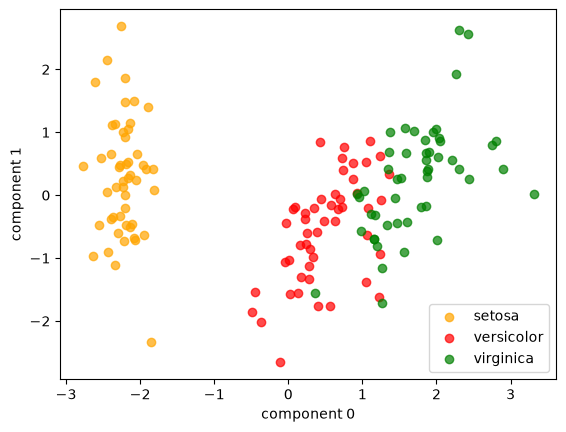

In [10]:
import matplotlib.pyplot as plt

# class target 정보 불러오기
df_pca['target'] = df_scaled['target']

# target 별 분리
df_pca_0 = df_pca[df_pca['target'] == 0]
df_pca_1 = df_pca[df_pca['target'] == 1]
df_pca_2 = df_pca[df_pca['target'] == 2]

# target 별 시각화
plt.scatter(df_pca_0['component 0'], df_pca_0['component 1'], color = 'orange', alpha = 0.7, label = 'setosa')
plt.scatter(df_pca_1['component 0'], df_pca_1['component 1'], color = 'red', alpha = 0.7, label = 'versicolor')
plt.scatter(df_pca_2['component 0'], df_pca_2['component 1'], color = 'green', alpha = 0.7, label = 'virginica')

plt.xlabel('component 0')
plt.ylabel('component 1')
plt.legend()
plt.show()

### t-SNE (t-distributed Stochastic Neighbor Embedding)

고차원에서의 데이터간 거리와 저차원으로 임베딩 후 데이터간 거리를 유사하게 유지하면서 차원 축소하는 비선형 변환

**t-분포**
![](https://lh3.googleusercontent.com/fife/AMPSemc3bWjEFkHcLEvbOrYUekcIQYJxMxLzPtwy0o6lR0j8BkFYXIOb_tHPh9K3AqYeihJo3Aowg6VxBvW3EjuDEXxBhS6c0MQ4yde3bcn4Ai17WOZaucmypy3A1UqOiYqFMYw1CsfJnwEpHoPFSTdlpMdFGHMM0pSLa1VfrBQIisHpn2yTYUXukxqskFMD_hFeXHiitj-_aS0suLiPTGcpM3KPZgW5GO8NkL-gUkQAkq5IR4NdV8T4Is-p8De3sEKhmGy93M-CDMES7VeJRw79lPW0n_lqG7XGBSbbdgFM2dO9vr5dGc6iFcTwZxRkTFi3-vuJ_meZe1gv_BGs64n3hR1LMPZRb9d0TrAwEkAPVEvGh17qvd9jYFKqlvv0hir9GGAFIbCDl2Kd1c48rikAssXUlkDgoSkuMNDJ6dPXhVphho8lzuKiiLJizp95qfW9x8zEdDLgHQv6HLdKPLsDVa-nwcvBIVQXAna2CEpktDJQaQYLRXsrXaHuQ5roDSzrYdspP0lhdEzAfGGK9l2GJ-9hm_wKPjxAkwQVC0_IQ0EWAegRSC-vmdgLdkilukgJ0li2_9jYrN4V6-i7vCf2FPJW5Z7HURG7WbmkDb_r5vgh8DcF6qSBC4J1bOtTkG-gZp6KxXEgf7I129bpDBdEUyt-CSZM12lUDj9soiKkVfvD-OcLr9VZcH9spdADm8pcum3rkQ1F8OPBGrJRERmAMZ0MY3H2rKzhSGiv0REapSPrOJsXe4z7TiJGwGIhCvZIUhfQ54v85tbdzqS-LG6DqmptCfwLU13EfL3a9ytXmhhxjZEUktwATDXbgo4fb7vaN1_wrb13f31uB_F7a4V2RRAhpvOZW0b7Qn1z6qqoD_adWW-HNbj-fcxeoIHaThZ6EUqO4hme6bAzqXsB4ixu6iA5h5oAexsqwFbhC2MXoCwDJ6f9V_WPuII_fNRw0D81X-owO5WjwBhSAx4ljyipH_q2C5munOycE_wDNWZBxfDq24h8pzOdZj6S9qHVpu8zr_yOX4PZrEchHJ7l_3-Ckx-DRrYkqzTNzYaIusTCb5UcMOvq5_ByDbjDvVR8PYAjYms44g2PjKBMm4_v5ANMFs6Csslbd_Ek-7Tne7jZcmONA2XRCNeCUwA06_bF3wH50sGRGu9rxIvHg-29X8gq6-4dj0eOdi9husMBK3HqVNfyxo2Lv6OC6JGgzGXkgj1tqfWPefVDY98MESEU-XkkHc9kSaZpPH853y3ieVo7OpQva2RxdGutiR_cG3i2Jb-YaWV8oEuLP-8yHQ4CAUsAR7cPg7Pc6nuMmhbWU35mpy8EgSS79Jn4qEdy-QQaJBUujqXdQVk4dfw0d9oi8EV0531HOWy_1lwukiadlYGragHWKRylChDP3PXwGqaOzLLwlr_hD1Wngu2-K4tkg8VXHmOMWiqQp4Wgm44x7qWNfexQPVMsZj36zjoonD4vEw3bIG4poakTRSoq02eBw0g7Dzk)

**t-SNE 기본원리**

실제 데이터들이 분포하고 있는 고차원에서의 데이터들간의 거리(유사도)를 저차원으로 압축했을 때도 비슷하게 유지하게끔 학습을 하는 것

![](https://lh3.googleusercontent.com/fife/AMPSemfuKDQm1qPRya19xY6DTl7-7gHMukE2eUa5RfDKIdtpuI4VsYAtJkJiCEUYm9ooxe2k9H1qH2tEk4oT7dZ44Mfi-jx40BiOlr68AorW4gFmMbm-gbKqMdv1uTUzPBEPTKBe7FxyXI4SsGHiLGlzdXjW_BhxAbmniF1NpOPg5HSNg4SEAboFC8AtRVSiGfJphX-NTsEovmXnfz1ZUaU-8yLKgovxLwc1lJOQNDJkjV_w-sEn-adorfSIPzJhsVBhEt6QMSAKvc37_ndnJzZh3SNtp7OwlDJW6yjWTHpLIPBkMiFqlxqOw0_Jg-nXNCF7uBwM7qbAFy2ubZvijKgwHnD94LYkPkWnG16wZF8KAVyHpsKxi547ep0kTgP6B4Awoketb3moY53wuIoETp-kZPg3HCEKnws4xp-lRC4oqN62ZZrOtovdYx5_eEF3UZrwhRjFhILi3fdTe5VIgGxpX7BdsXhZbTIqh8OK0rnBKWNxlXCRm6SBhpNkqOam5zjm-pOlTlROzMi6c4y_ua1vBenPWG8JWhuTEvQdwOU2lDac8mQRc_Lx7OF7yKVXfbkIRAmVAQoOv8ll893iI4MlXZzqWrWGJubRllsGPTC4sxVSex-R22EZ0xubk9t_RW9U6NiPCeSkBtWfNsJKt65dyaLBKF66Iy5wYbTWYJvHUbZup78dWTbpo-hXavqO-iuN24mquRXAVpAQjVj7PyD8s0O4JedBqgpn_xbIeS9TQ-3C7KfRy2pB6x3vd0dq95QQF2-_-R4-iEIpeYDRCO5uQrV2gMUpqpbeftI1HIKee91qTBrCpx8-j19FCUXPcKHDPwUvo03O83P4eObEQoBf23ajANP13IzBiSOdOwUac2ij4JTSpBN-w3ErIB2ina6jBK7yAk4IcLFeflRIweVe0Mrnq2FFeu4wK8nd6f6cthxeRHUWO_sewuhKUaY0JuaPpNa4DqGYHec7YK9LT6XjZVsbnGNbgChgFyfX5zLlqfWWCuwE3WkOfxboCx-QjdApMHYOnLUxC-UQPOExPaNedzNl0j_RSwH1tqYiGRHT3C5by1BCc-CotI3UGpt6W1J9KwUPUTlXjY5cBhS7bJ6N2UAiqpV_gHKOzoCXhRGJ8mLgoAlSJ1tOFMcbR7MLcJEVu3HenBxF1NoEDNtPLPPtp3KbN8ECUwr8IwfoJ-OaVzZElb4cDHWi9PQpuMG7s-CLlUGpGtwycbahonOQr-xfYQ2Eh9BnSrcAedMC8DmuWNCzAJnid8KU8ntwvL4oayjQa0SY8frTkY76IqPt9w1bwpjC-Dyi5x-AiupGvMZwvLPTkXuQw46mbancSfi1jTcsCMBx4cKJyJI0XLu4B-A6Lv9lYvobM0SeaPum6zCMJcO7SAI42odpexQjQWDigBFEEKQpINeytJYiSSmuJmyoM_jNhYX-ce-9D_XRr3vIFenUWlXRGGGmXSmncBHhrXcBK53HnoNNYBDyVPVxS5QnCzc)

**데이터간의 거리(유사도)를 구하는 방법**

고차원에서의 데이터 거리

$p_{ij}=\frac{P_{i|j}+P_{j|i}}{2n}$

저차원에서의 데이터 거리

$q_{ij}=\frac{(1+|y_i-y_j|^2)^{-1}}{\sum_{k\neq l}(1+|y_k-y_l|^2)^{-1}}$



고차원의 원래의 데이터는 정규분포를, 저차원으로 임베딩 된 데이터는 t 분포를 이용하여 데이터간의 거리(유사도)를 구함

![](https://lh3.googleusercontent.com/fife/AMPSemdUUS8H1q-w1oEMj2Ys6GIu0rEsMoW7BSvp4nGF1vCciyKCqWL7HUCtHgReIcPpVkYILABka2pZWXRYtJgVIXjfS1KiTpGdmxKyVSQm_6zFvpghsQiuKL8ucFDYvJJFeA9FhAlX7sQgHyaaxchoKTCK1Djn2Atg1L1pTeEvmYyQ3zURK_63Cs4-tmEIFRwSI7KLvKYMyVIiYSlKrrTqEw4knNWWXggDZ5l-unSy5JZvZBD_uH9my_GDF8b32xd2B4xPsaVTxjDEYIDxwpSS8UtNznTboSpmpec1ihTZR5vEV7qRn_z3OQ-9W7eM6_yYdbT-2KBCH68NjUBy2VAcScMTBVk38x2fHY6tq9ceEGBrO3hLRFRF06G6x8yfx4jpdOYyCX7-BGnj0-b1UZ1JMqSdXACL1J0WBqOBOpbsu3LR1Y_Bj4K717mmAy_-KzdGmizB_98QgcUBE7_iyclLx2Jq1OffhCT9R7B5thUvyMDFIFUePHBGqnohhPlbaKZtbP7WhhOffkXX9Pi4GlrONRSoPb5juud8qLwzfe6T2DqMLhONJA7nB1OajE24aXptsonApuG1Sz_-0jDUqMeAUEGfS9htrDTT4yDsLva96JMvBsSqW1TyVN0YW5VUHbZJlEfAGu-P4LH0uZsv0iW5z10y3LaSmCiq_hidXEc-z6tnlEKZV878oUFjk0meMVdfOCjp8At5Y-RiFv-m5vSaTQlhMXqNb8kVXY_vGoeP2XrWyMOi_8qJA-m779Tt6v0gWc0NygCQvxzx515HMfisxnVOOuUnYBgrEJHN8jx4cCgLguYNk5U3lgsGuxbQzJ5iu8_va8aaVbfwPl9_PQh-GfVYYDy9oZ4EtVgEsvQELhv5zfN2flU4P3MQMP0P8L1O8ZaTbuW8eKsuzoYJpmcHaBg_4i10mIIq7bvENabSgYJPJT9iRoQV5-SM0dnmG7kIfh6nf8nl9hCZ0tyD9zRkT8e79lcydERdPD515VeFv7iNJeKRKJ81xwA6xPOaLTyQnhFXsA-yTsnA772G4pw4tY4vUc2v0YJxqVISc3IIX5wJJ_KquBWvl3pQExwCwVgge2sVoBrv1q6sG7-sVVcmoSejs_vZgzTtNIew3KJe2KwgaQckzkxKMOCfvtCDnXzHpcprxRg-7wgVzMhiARbdrLW4Xo3LFnT-tv5rQ30RrASjtZdujNmz8z79lTL8z560rbCJO-WBDaIQlD3xMhFL78iLNipsMsCVFNY8z4NGCkzC2KZ_lIwkXCNZJsPrjaQ9-dPUjEcdBdfj2ABpYnPo97fZE8Rfi7OSQjnrLsat85NdBoHITi4pWwqlYL1aORRLv8Ap_kZl8A_lbeX2Oyn29I1x5p7cG_Nt3Y_vq51s2uuUPkmuIxDSVjygk75SJI35YQaApGp_sfD-KI28nNNZ1cGvywPBPoMBT3byHNMIbvAWAAEHKU1g2zCOVynNBTyHyfOffPVGHBZqin4x_j6YuUo)

손글씨 데이터인 MNIST를 가시화 한 결과

![](https://lh3.googleusercontent.com/fife/AMPSemdsGEwv4HH2fmJhjMqlStFr7Y8G4Y_UUmtA5HhEtNMW9pRjO3H9mA69rMZQsGrI0KZl9nav0650-ldtE4su4IcTtPJm77j9ywSHYZHAKbcbS7rTSW-wsjBeLC_R-II3bdZLTmGqfGPaNsbHphEaPA12X9PKivEByy7L9LvQtm-NhsssDR8eM8xDXcs3v0-5VVtFGixaui0KY8pJG7yhX7U6C9H_dpVZLX3O9SC2Ls7pxcYTt22pvDgHb9ohW1AUQn7-A2WcYiWOEf8vX2bgCDq-pmNvJhm6hmgOflnSyxdyNOkzM1LBYLu1jwa9Pr7Yn7p2sxqi_KOyRqVvhnWp4McSrjb1nfqOHc3gjSGnqW0GkurbzYfniCZZwgon8cI2q-sr_j6B4ucveV_Rmrq_eM85OypUMxYYOZF-kZDPQpK1vqrDc4zeoAKw3cR50g80i0DijJYDtBsI-nak0wNOTAk3R3dzG78MxhXR3DvgZZVR_9uAVihV_VI5rM4Hb1vny_CB64ULsa6VtUfU1WOmaVJYWgqRn75wVm9Ff3a9e6j9_mG0Z7oWMBXWWbPrIuAvyRR2wNYfkS-DNs8M1y0q7VlAd50yoWVFQcE50O-8PIQkse-C3TvmPitsETuPtCCrKRdVxHYWYY3B0bI4uphJj0gOPCLrI1ZDLJY3ToNLvyfvdKrWOsEKj-o7EUnt7igRxDVuOSDY2NyazJLBeZvrWmDD692Xfs6ZcUBF61RtGDJ33KQMEqbmdkw1bLhnBI9DuoLOodVwXe7CCrrJy8j7ngbf8XE6tzh1YAJbdBsfVNCXzzi8qyMl1lYxpQJRwdlC3oCBXjIvaZP9-Zzce6ehBgF5CUnaMFSew12XTBkRWxNWzCdN13sf_jBnWhKdOGJlh0z04ZvSg9YMTMG_C6c_XWxUhfQni5OCqs_Lncx4NPiCUS8JydqK8QTJypGY8yFqyTCtEDCESmhgmP9pewqUkO6aUmIgFx-Ex69w45nt7_pF0UAn2vHA3AaWJsqKVKWkcW8ZpgqgkEmRRbDp7U4f8xiZibcqjZKuehoJ0S6Yo81uwPoioFj2zbN5CY0OOIiWOUCyTfPmHavDrBI32WSvaTQOpRibjR50oe5NBO9u-5VyhfVBCbAHL0k0k8mKACQBscyOP7aFF5dnMoaieigZ8cwEoe5iQh2NLm-S9IjuyruZZ7meoDTOZP4eTlXoclUJAma46fsCMHYkQo560gERlN6Bs0XNktQtjepiLSsjtzsw3Fqq59q3cufQ76g4z2ozqrJq6vkLAnQUdjojdk4SnYz82OtPyPZlhBv7f7cOE1pR3aJwRGQ66w-BUzsruYhwxVbqANbnIrjEhZP7UZRYITqJW8o2ATYqP2WEInyC3GcDmjSBqtlqrWcJ6TJQyT9U5rSIRzZ4yQyODYuknn_gcfSnuVnybIiSPxma1rbs2HV7jQPTkszGvtdKTJD_sDsNK9vaBnIogTBQki5RHwZzp6w)

PCA에서 사용한 데이터를 그대로 가지고 t-SNE를 해보자

In [11]:
from sklearn.manifold import TSNE

# 2차원 t-SNE 임베딩, target 정보는 제외
tsne = TSNE(n_components = 2)
df_tsne = tsne.fit_transform(df_scaled.iloc[:,:-1])

# 데이터프레임으로 자료형 변경
df_tsne = pd.DataFrame(df_tsne, columns = ['component 0', 'component 1'])

df_tsne

,component 0,component 1
0,-24.310734,-2.112274
1,-20.536928,-1.383607
2,-21.545553,-2.416494
3,-20.773043,-2.460989
4,-24.798649,-2.687798
...,...,...
145,13.285615,0.528409
146,8.565119,-0.525439
147,12.132917,0.741809
148,13.861059,-1.138135


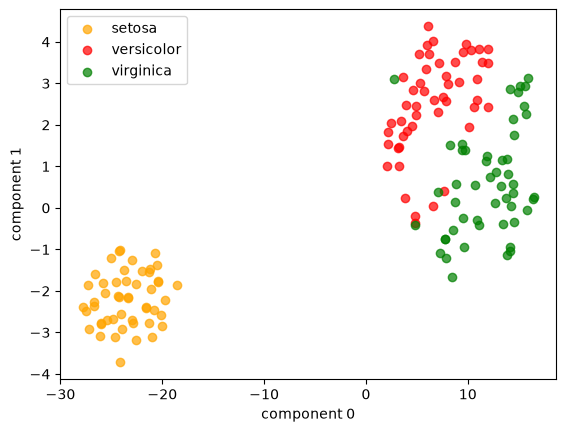

In [12]:
import matplotlib.pyplot as plt

# class target 정보 불러오기
df_tsne['target'] = df_scaled['target']

# target 별 분리
df_tsne_0 = df_tsne[df_tsne['target'] == 0]
df_tsne_1 = df_tsne[df_tsne['target'] == 1]
df_tsne_2 = df_tsne[df_tsne['target'] == 2]

# target 별 시각화
plt.scatter(df_tsne_0['component 0'], df_tsne_0['component 1'], color = 'orange', alpha = 0.7, label = 'setosa')
plt.scatter(df_tsne_1['component 0'], df_tsne_1['component 1'], color = 'red', alpha = 0.7, label = 'versicolor')
plt.scatter(df_tsne_2['component 0'], df_tsne_2['component 1'], color = 'green', alpha = 0.7, label = 'virginica')

plt.xlabel('component 0')
plt.ylabel('component 1')
plt.legend()
plt.show()

t-SNE 장점과 단점

장점

* PCA의 경우 데이터를 저차원으로 임베딩할 때 겹쳐서 뭉게지는 부분이 많이 생기지만 t-SNE는 그런 문제에서 많이 해소됨

* 기존 SNE보다 t-SNE로 사용하면서 특정 거리 이상에서는 학습이 반영되지 않았던 문제를 해결

* 하이퍼파라미터의 영향이 적고 이상치에 강인함

단점

* 시간이 오래 걸림

* 너무 높은 차원을 한번에 저차원으로 축소 불가능

* 저차원 임베딩 결과가 실제 데이터 거리를 의미하지 않음. 군집의 크기 역시 의미 없음

* 저차원 임베딩 시 정보 손실과 데이터 왜곡

* 랜덤으로 저차원에 매핑되면서 매번 돌릴 때 마다 결과가 달라짐

### UMAP(Uniform Manifold Approximation and Projection)

고차원에서의 그래프와 저차원에서의 그래프를 유사하게 최적화하여 변환하는 기법

t-SNE의 문제점을 많이 해결하였다. t-SNE에 비해 시간이 현저히 빨라졌으며(45분->3분) 데이터 특징을 학습하는 목적에 더 적절한 수학적 이론을 바탕으로 global한 구조를 잘 유지함

**UMAP의 원리**

두 데이터를 node로 볼 수 있고, 각 데이터 사이의 확률이 그 둘을 잇는 edge의 weight라고 생각

고차원에서 각 데이터의 graph 관계를 저차원으로 임베딩 했을 때도 유사하게 잘 유지가 될 수 있도록 하는 학습


"**fuzzy simplicial complex**"를 구성 ~ 모호한 단순 복합체?

![](https://lh3.googleusercontent.com/fife/AMPSemfMdQpkdIm_wRBSlggWRQ926W6elABKCHS0WktUFGtsN0MHSq5_zosb9sJDEQuAsIqlLh6ECQb4mY9ultl7i-G7A44DbsjYk80ISggU14FDnG63Oa74_yasrGp72KMPUZ-U-AmIK327nqtWcGBqPf74Nz3xZL51nMcY5NYgw_sh8DngU-yDAdAOVLwcC03Vfu9Xg1pBy3sw1VNybjpzPTwBKgfdt-FC7cLa2Ptqz_OVYRebqgnfR9FGQR3vc6Sd_lSz922tQKtbKFUuwJ8JILeuAmw0VWcdM1okboFgQZXSEMeCErMnEAPUvEfJZGuwEaq5jq9bESbEY0jRzTaunK1qPcuJ1Dc4heMmD4qDwBya1SCMz4JYIVvk1PnCIA_wc8E8qnP_D-E4yxZYyuqbMM9JE1PAGFwY5xmTo4PHb4MNZyrpJuoxFdLRNqlzydo7KIb3_xsa0by49l6uIYiIBPs3fFsUoMfj_bpCv92-2VPTqXZZxN0cfVXETaNjvKFTgwesmSLWFrCEJ73oZN7Zuam8krLzQot0yCWpHkNVHOSsQ8yIIKJdBTywZeggNrjXg0SVlLjz3QZPCUSSAd6FYIuwI60toCASDvAhABfnAHEBymcwSBGfJs26QfX_q3HNUe0Ve0PkSU6jjtr9NuRlnK6ZTRiW5u4UqRxrL6taTyTtYrbNouCi32lgDA96sXRVaInegRZ9B4ghz9HMjICzWHPA9wdGLxtaBUTdavLg5h7FOfuzr7-tMURAowmtz2ULborD-sqQAfeCTvoRMrXKe2F2IiquEE83XJujrIaLjwx6YWP9puhHj35ss6wghVR8JqJqjGon_zAsETwdKLtm7HOiVN4RYACMs6c11EIkS3U6d44PQ93NvO3xmww7D7p0uSYH-2_ZkB76AlzaHiRbUM7jc2IqYnN-HEfzPu5LI_KC4xN6igZlweDRTwa-btqt7cVGnYaVyhmByvBwpDxgLYd78qIf8w2OmF0BlQXLnevnQNqJATqdv3Sbkad38nuyw65M1cXYtxW2MO8jfFIWmrJaMIfIcnrHHZp7YiUgH4qdbdXdqjtFZj2sEfpvCSlGBBzWZ8JUNiyWtV-ZvP_d_eRkSPJ571dih5RQy5hXk1mBqxyME9WmUmo0HZNzrmjQo6mccYLbj-5rGLiRoXjcGJE6mTGzd_pdWFY9PiySTkA6eRsn5d9w69ILvVR_tO242VwXGB_lbu6eTVciJN0gHx1pUScCm7MPxW3eSeB_68TePHohujEac37cNi2qKIwIji5J9qkkrRmknhhLBNRh3PzlbLmww99_QLQgQcCf4zQXBC8HqPTyL5CuyREStRzS33pLLMpFoSlT6-Kk5g_VG_rRQryFJQu9m3w5Wv7PFCTUCnGP6zABfjauK9y8keovdVuy6JGo729I0KovJY1F2S2lfOfFotsRY3DyHHRmCFH5uGy0TgZQgzCYIIqpeVTovL8eYQfO4vHSZ-GCeIOpzTU)

extent = 값이 커질수록 각 데이터 주변의 범위(반지름)이 커짐

n-nearest = n번째로 가까운 점 까지의 거리, 값이 커질수록 각 데이터가 연결된 다른 데이터의 수가 늘어남

두 포인트의 원이 포개지면 두 점이 연결되어 있다고 생각!

이 때 이 원의 반지름이 중요한데 너무 작으면 작고 고립된 클러스터를 생성하도록 유도하고 너무 크면 모든게 연결되기 때문

n-nearest를 통해 **포인트마다 반지름을 선택**한다 = 포인트마다 반지름의 확장속도가 다른데 n번째로 가까운 점의 거리가 짧을수록 반지름 길이가 천천히 커진다

UMAP의 **반지름이 커짐에 따라 그래프를 fuzzy(경계가 불분명)하게** 만들어 점 사이의 연결정도를 줄인다

각 포인트들은 **최소한 가장 가까운 점들과는 반드시 연결**되어 있어야 한다

https://pair-code.github.io/understanding-umap/

UMAP의 파라미터

* n_neighbors : n번째로 가까운 점 까지의 거리로 이 값이 크면 global structure에 집중된다

* min_dist : 저차원 공간에서 포인트 간의 최소 거리로 포인트들을 얼마나 촘촘하게 묶을 지를 조절한다

Fasion MNIST를 UMAP과 t-SNE를 가시화한 결과
![](https://lh3.googleusercontent.com/fife/AMPSemetUPFpS1oToQu3nGIWaTSTKddfH4g9FqRiX6UVRNi_cvfkm-yrr1tsc_XvjUQ_V0V_uAsMktUDuRGp9iwWzC3qgVf-JOikcKYsG2aOxEFPE4YlyRavf9nLAsRkNCijjpLVuroSTWnF3j1mUKtqfiZc9EMlJsxiEcFfHSjpq5ebkA_4k-gv6S-8N8wY5dkxbeyUQKzxIp-9QHX5YtC-elq6gvXpndW0R5NSJpvgRhc1KedpqXcNlDYsdbeCcc78cpjBQO72zJZP30EDomlOYgV8Rdwf0ZeYNvo4FRYSFbyxUYj76IQJReodzTxNpnEOiEXKrOloOZRk1aHtnKnxQDbc_vgQsbK9KbrbD5eR1gysX7Ofb0na2IcHoYkImdM239V1wETD78XXHnwA1UHQM3xoPEjfY50433ujA6gldHt5XbHRt9mKQVPTDPVbQtWXNpO5lLRniF8G-SCMIl-24suGvvQlfVr7R38PwlYMHVF3QFqcwnMqsRpYCsxGDYjnfviWD8nXIpN-CrjrNG69W_-zf-7XzQ6xI0T8z0OstiA_FAW_7k8dYEoy_gK0nmqpocmGL-GsaowAegcIjEBTMjEkFI6e3cdFWUQoPlMhoHj-qc5ADlitfOoflUbqZMGlkKVulIiGKkqBJNygfHG1p6klpyHI2nq3Hlgubk6YBaYqVJtUPLtFHUS1WgTVJwE5RuDFneMXzVraibe2n4SQLj4g8qXGE_1qMrvqavmqnvPtKoxsbgzCmPZKhgDDXDDVIPMXhScZkeGoTS-2KVvrYlfcUdpEjbLqlBRYxlgmaTc3gN2ctoZYshaWdysiIrtPvZn9djXlaE0XJk_V3JWOlrgkqbMUz9UqMhoPjKnbxJtxaEg5_7yYpE9xVqIOqIu2srDrENRXQLu8dvbqV9gNrPJPnwVr8Z_iXyAGqHqesJUaQbSIgUmgFC1s-OqcluPNSvAVXBNn-Lf7HHH7CRvyRWi38lB9tzDL5PSA8v4OyDoJ0FsoRkVzS-LHBxgDPltk3Cao-hhgGM3Nki9Pg5AO_f-1TxoWxSMZHVKKG-e8ZxtK20IHAyRenILEZZw7A6MmPuCnjXsTVdJ6Sl6GO6rW9fglUyMCcFG6FO5AnHViLHfJviYKXj-g2KtWFm1Ggs-nf2TwsVHHNLEl4BUqtFVVtM0AfeR8Cx9ABRTRc_DmtIYIoIFjWwPnoKdLcEmKKZwyhAwr7KKgaKQJ49j_93uK2GNppYrdeUego7GYf_I1NKRY3pOMSI-zX96hzuWFJbJNEG8Tj38cA2uP3YiPaZjvckq7E_ecrNhnpu2UjfdpIegiz5V1tH0yO5pd4v1dyoWNaKDbkBIw7NQIM4t_l6KOA83eiP7LwxfFgBD-r0s8tySNG6YtlNjxT4JveUaFXx8jDxHsLmlOgb2s4VTorv9Qmc5Dl41tvcS_45As6hOM54IPOPD3oTD-OcqIwLJt0RPuCHJWMwQRLsWSORIinpjizD8)

UMAP은 코랩에 설치되어 있지 않으므로 설치가 필요하다

In [13]:
!pip install umap-learn[plot]
!pip install holoviews
!pip install -U ipykernel

In [14]:
from umap import UMAP

In [15]:
# 2차원 UMAP 임베딩, target 정보는 제외
umap = UMAP(n_components = 2)
df_umap = umap.fit_transform(df_scaled.iloc[:,:-1])

# 데이터프레임으로 자료형 변경
df_umap = pd.DataFrame(df_umap, columns = ['component 0', 'component 1'])

df_umap

,component 0,component 1
0,-5.715446,7.441088
1,-5.271786,10.346782
2,-5.091326,9.552155
3,-5.079820,9.986017
4,-5.538651,7.085798
...,...,...
145,13.811639,5.192873
146,13.541246,7.953403
147,13.979078,5.792165
148,13.034477,5.186412


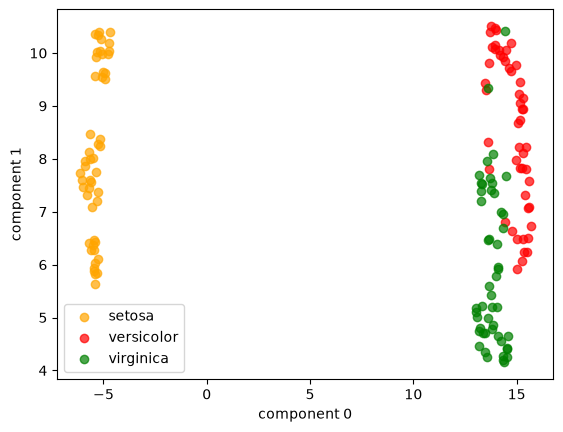

In [16]:
import matplotlib.pyplot as plt

# class target 정보 불러오기
df_umap['target'] = df_scaled['target']

# target 별 분리
df_umap_0 = df_umap[df_umap['target'] == 0]
df_umap_1 = df_umap[df_umap['target'] == 1]
df_umap_2 = df_umap[df_umap['target'] == 2]

# target 별 시각화
plt.scatter(df_umap_0['component 0'], df_umap_0['component 1'], color = 'orange', alpha = 0.7, label = 'setosa')
plt.scatter(df_umap_1['component 0'], df_umap_1['component 1'], color = 'red', alpha = 0.7, label = 'versicolor')
plt.scatter(df_umap_2['component 0'], df_umap_2['component 1'], color = 'green', alpha = 0.7, label = 'virginica')

plt.xlabel('component 0')
plt.ylabel('component 1')
plt.legend()
plt.show()

## AutoEncoder

딥러닝에서의 비지도 학습으로 단순히 입력을 출력으로 복사하는 방법을 학습하는 신경망이다.

이 때 여러 가지 제약을 준다.

* hidden layer의 뉴런 수를 input layer(입력층) 보다 작게해서 데이터를 압축(차원을 축소)한다

  ![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F996C93475BDC97C00A)

* 입력 데이터에 노이즈(noise)를 추가한 후 원본 입력을 복원할 수 있도록 네트워크를 학습시킨다.

훈련하는 동안 오토인코더에 제약을 가해서 데이터에 있는 **패턴**을 찾아 활용하게 하는 것!

* 인코더(Encoder): 입력을 내부 표현으로 바꿈(인지 네트워크, recognition network)
* 디코더(Decoder): 내부 표현을 출력으로 바꿈(생성 네트워크, generative network)

=> 인코더는 정보를 받아 압축하고, 디코더는 압축된 표현을 풀어 입력을 복원하는 역할을 한다.

 ### 오토인코더 구현

 '펭귄브로의 3분 딥러닝 파이토치맛'교재를 바탕으로 작성

 https://dacon.io/codeshare/4551

In [17]:
import torch
import torchvision
import torch.nn.functional as F
from torch import nn, optim
from torchvision import transforms, datasets

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D #생성되는 이미지를 관찰하기 위함입니다. 3차원 플롯을 그리는 용도입니다.
from matplotlib import cm # 데이터포인트에 색상을 입히는 것에 사용됩니다.
import numpy as np

In [18]:
# 하이퍼파라미터 준비
EPOCH = 10
BATCH_SIZE = 64
USE_CUDA = torch.cuda.is_available()
DEVICE = torch.device("cuda" if USE_CUDA else "cpu")
print("Using Device:", DEVICE)

Using Device: cuda


Fasion MNIST 데이터셋을 사용해보자

In [19]:
# Fashion MNIST 데이터셋 불러오기 (학습데이터만 사용)
trainset = datasets.FashionMNIST(
    root      = './.data/',
    train     = True,
    download  = True,
    transform = transforms.ToTensor()
)
train_loader = torch.utils.data.DataLoader(
    dataset     = trainset,
    batch_size  = BATCH_SIZE,
    shuffle     = True,
    num_workers = 2
)

100%|██████████| 26.4M/26.4M [00:12<00:00, 2.12MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 113kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.88MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.14MB/s]


오토인코더의 모듈 정의

In [20]:
# 오토인코더 모듈 정의
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()

        #인코더는 간단한 신경망으로 분류모델처럼 생겼습니다.
        self.encoder = nn.Sequential( # nn.Sequential을 사용해 encoder와 decoder 두 모듈로 묶어줍니다.
            nn.Linear(28*28, 128), #차원을 28*28에서 점차 줄여나갑니다.
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, 3),   # 입력의 특징을 3차원으로 압축합니다 (출력값이 바로 잠재변수가 됩니다.)
        )
        self.decoder = nn.Sequential(
            nn.Linear(3, 12), #디코더는 차원을 점차 28*28로 복원합니다.
            nn.ReLU(),
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Sigmoid(),       # 픽셀당 0과 1 사이로 값을 출력하는 sigmoid()함수를 추가합니다.
        )

    def forward(self, x):
        encoded = self.encoder(x) # encoder는 encoded라는 잠재변수를 만들고
        decoded = self.decoder(encoded) # decoder를 통해 decoded라는 복원이미지를 만듭니다.
        return encoded, decoded

optimizer와 손실함수 정의

In [21]:
autoencoder = Autoencoder().to(DEVICE)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.005)
# Adam()을 최적화함수로 사용합니다. Adam은 SGD의 변형함수이며 학습중인 기울기를 참고하여 학습 속도를 자동으로 변화시킵니다.
criterion = nn.MSELoss() #원본값과 디코더에서 나온 값의 차이를 계산하기 위해 평균제곱오차(Mean Squared Loss) 오차함수를 사용합니다.

5개의 이미지가 어떻게 모델을 통해 바뀌는 지 관찰을 위해 view_data 정의

In [22]:
# 원본 이미지를 시각화 하기 (첫번째 열)
view_data = trainset.data[:5].view(-1, 28*28)
# 복원이 어떻게 되는지 관찰하기 위해 5개의 이미지를 가져와 바로 넣어보겠습니다.
view_data = view_data.type(torch.FloatTensor)/255.
#픽셀의 색상값이 0~255이므로 모델이 인식하는 0부터 1사이의 값으로 만들기 위해 255로 나눠줍니다.

학습을 위한 코드

In [23]:
# 학습하기 위한 함수
def train(autoencoder, train_loader):
    autoencoder.train()
    for step, (x, label) in enumerate(train_loader):
        x = x.view(-1, 28*28).to(DEVICE)
        y = x.view(-1, 28*28).to(DEVICE) #x(입력)와 y(대상 레이블)모두 원본이미지(x)인 것을 주의해야 합니다.
        label = label.to(DEVICE)

        encoded, decoded = autoencoder(x)

        loss = criterion(decoded, y) # decoded와 원본이미지(y) 사이의 평균제곱오차를 구합니다
        optimizer.zero_grad() #기울기에 대한 정보를 초기화합니다.
        loss.backward() # 기울기를 구합니다.
        optimizer.step() #최적화를 진행합니다.

epoch가 돌 때마다 view_data가 decoder를 통해 어떤 이미지를 생성했는 지 확인하기

[Epoch 1]


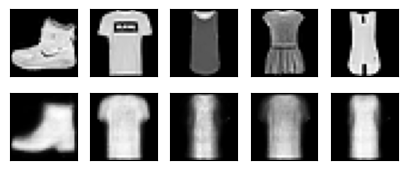

[Epoch 2]


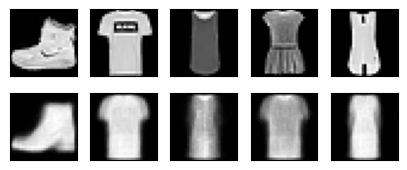

[Epoch 3]


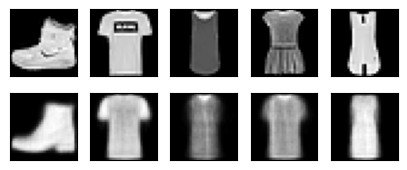

[Epoch 4]


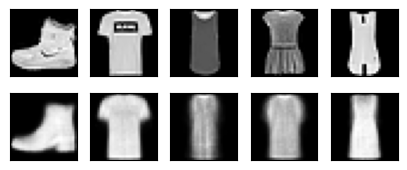

[Epoch 5]


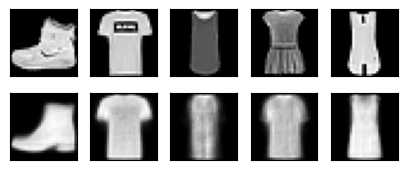

[Epoch 6]


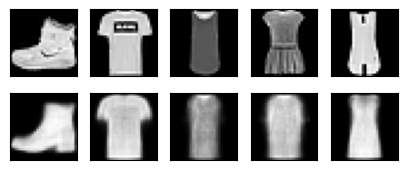

[Epoch 7]


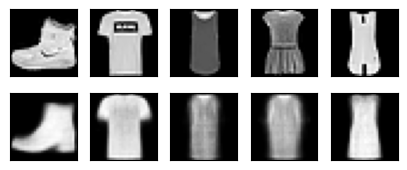

[Epoch 8]


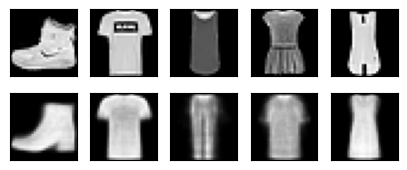

[Epoch 9]


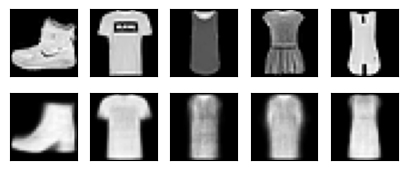

[Epoch 10]


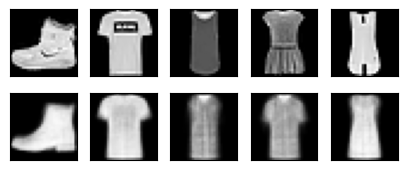

In [24]:
#학습하기
for epoch in range(1, EPOCH+1):
    train(autoencoder, train_loader)

    # 디코더에서 나온 이미지를 시각화 하기
    # 앞서 시각화를 위해 남겨둔 5개의 이미지를 한 이폭만큼 학습을 마친 모델에 넣어 복원이미지를 만듭니다.
    test_x = view_data.to(DEVICE)
    _, decoded_data = autoencoder(test_x)

    # 원본과 디코딩 결과 비교해보기
    f, a = plt.subplots(2, 5, figsize=(5, 2))
    print("[Epoch {}]".format(epoch))
    for i in range(5):
        img = np.reshape(view_data.data.numpy()[i],(28, 28)) #파이토치 텐서를 넘파이로 변환합니다.
        a[0][i].imshow(img, cmap='gray')
        a[0][i].set_xticks(()); a[0][i].set_yticks(())

    for i in range(5):
        img = np.reshape(decoded_data.to("cpu").data.numpy()[i], (28, 28))
        # CUDA를 사용하면 모델 출력값이 GPU에 남아있으므로 .to("cpu") 함수로 일반메모리로 가져와 numpy행렬로 변환합니다.
        # cpu를 사용할때에도 같은 코드를 사용해도 무방합니다.
        a[1][i].imshow(img, cmap='gray')
        a[1][i].set_xticks(()); a[1][i].set_yticks(())
    plt.show()

그럼 인코더를 통해 나온 값을 확인해보자

In [25]:
# 잠재변수를 3D 플롯으로 시각화
view_data = trainset.data[:200].view(-1, 28*28) #원본이미지 200개를 준비합니다
view_data = view_data.type(torch.FloatTensor)/255.
test_x = view_data.to(DEVICE)
encoded_data, _ = autoencoder(test_x)
encoded_data = encoded_data.to("cpu")

3D 평면에다 각 class별로 어떻게 모여있을까?

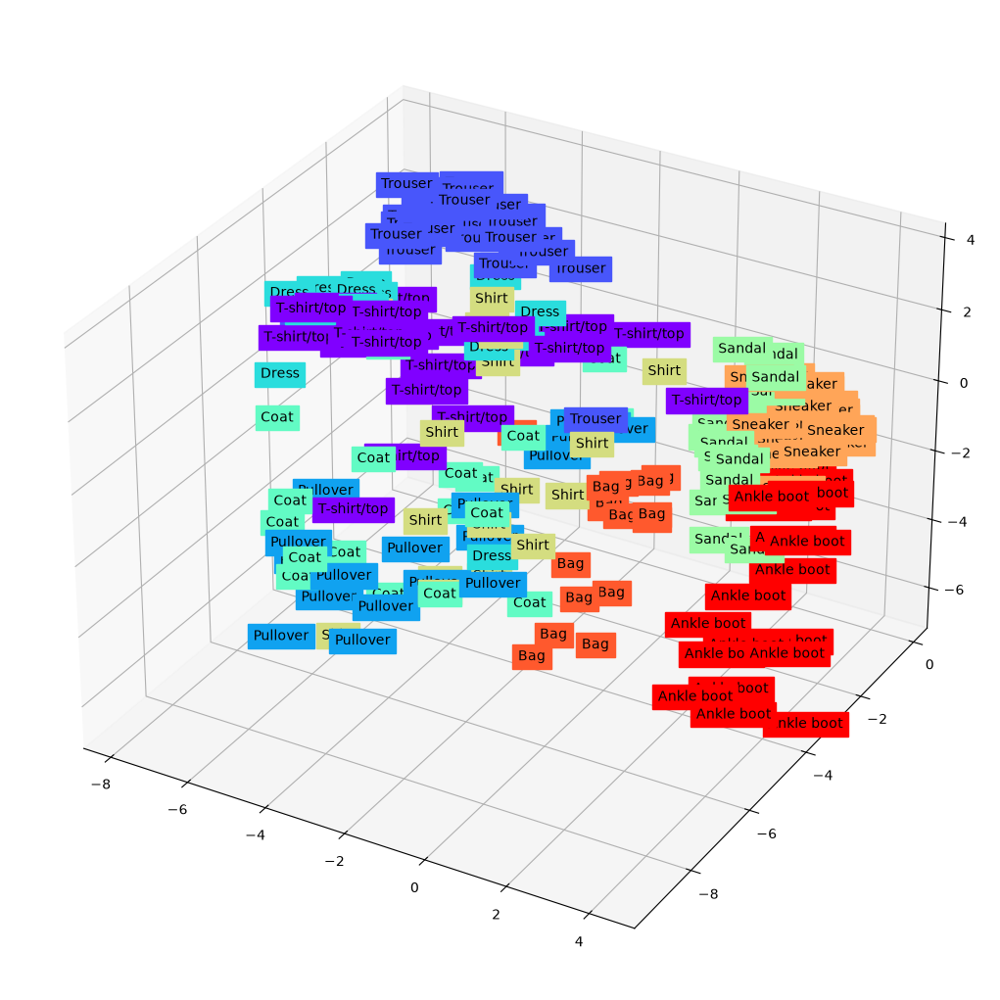

In [26]:
CLASSES = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle boot'
}

fig = plt.figure(figsize=(15,13))
ax = fig.add_subplot(111, projection='3d')
# ax = Axes3D(fig)

X = encoded_data.data[:, 0].numpy()
Y = encoded_data.data[:, 1].numpy()
Z = encoded_data.data[:, 2].numpy() #잠재변수의 각 차원을 numpy행렬로 변환합니다.

labels = trainset.targets[:200].numpy() #레이블도 넘파이행렬로 변환합니다.

for x, y, z, s in zip(X, Y, Z, labels): #zip()은 같은 길이의 행렬들을 모아 순서대로 묶어줍니다.
    name = CLASSES[s]
    color = cm.rainbow(int(255*s/9))
    ax.text(x, y, z, name, backgroundcolor=color)

ax.set_xlim(X.min(), X.max())
ax.set_ylim(Y.min(), Y.max())
ax.set_zlim(Z.min(), Z.max())
plt.show()

같은 레이블을 가진 이미지의 잠재변수는 확연히 서로 모임을 알 수 있다

==> Dimension Reduction

이를 통해 왜 이름이 **오토**인코더인지 알 수 있다.
![이미지](https://pebpung.github.io/assets/img/2021-09-11/AutoEncoder-1/Untitled.png)

압축 과정에서 추출한 의미 있는 데이터 Z를 보통 latent vector라고 부른다.

여기서 중요한 점은 Auto Encoder가 출력하는 latent vector를 미리 알 수 없다는 사실이다. 우리는 단지 3차원으로 데이터를 압축하라는 명령을 내렸을 뿐, 이후에는 모델이 알아서 중요한 latent vector를 찾아 준 것이다. 즉, Encoder 모델이 학습을 통해 자동적(automatically)으로 latent vector를 찾아준 것.


그래서 우리는 고차원 데이터를 잘 표현해주는 latent vector를 자동으로 추출해주는 모델을 Auto Encoder라 부른다

### 오토인코더로 잡음 제거하기

In [27]:
# 잡음 더하기
def add_noise(img):
    noise = torch.randn(img.size()) * 0.2
    # 무작위 작음은 torch.randn() 함수로 만들고 img.size()를 넣어 이미지와 같은 크기의 잡음을 만듭니다.
    # 잡음의 강도는 임의로 0.2로 정했습니다.
    noisy_img = img + noise
    return noisy_img

In [28]:
#학습코드에 노이즈더하기 코드 한줄을 추가합니다.
def train(autoencoder, train_loader):
    autoencoder.train()
    avg_loss = 0
    for step, (x, label) in enumerate(train_loader):
        noisy_x = add_noise(x)  # 입력에 노이즈 더하기
        noisy_x = noisy_x.view(-1, 28*28).to(DEVICE)
        y = x.view(-1, 28*28).to(DEVICE)

        label = label.to(DEVICE)
        encoded, decoded = autoencoder(noisy_x)

        loss = criterion(decoded, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        avg_loss += loss.item() # 이번에는 평균 오찻값을 관찰하겠습니다.
    return avg_loss / len(train_loader)

In [29]:
for epoch in range(1, EPOCH+1):
    loss = train(autoencoder, train_loader)
    print("[Epoch {}] loss:{}".format(epoch, loss))
    # 이번 예제에선 학습시 시각화를 건너 뜁니다

[Epoch 1] loss:0.023112135468674366
[Epoch 2] loss:0.022666046352211092
[Epoch 3] loss:0.02252472167822725
[Epoch 4] loss:0.022424877367055875
[Epoch 5] loss:0.02234117606722279
[Epoch 6] loss:0.022256966080588064
[Epoch 7] loss:0.022168732200588372
[Epoch 8] loss:0.02211580203294055
[Epoch 9] loss:0.022084421676788122
[Epoch 10] loss:0.02205457136249428


In [30]:
# 잡음제거 시각화
# 모델이 학습시 본적이 없는 데이터로 검증하기 위해 테스트 데이터셋을 가져옵니다.
testset = datasets.FashionMNIST(
    root      = './.data/',
    train     = False, #test데이터셋
    download  = True,
    transform = transforms.ToTensor()
)

# 테스트셋에서 이미지 한장을 가져옵니다.
sample_data = testset.data[0].view(-1, 28*28) #1차원 행렬로 변환합니다
sample_data = sample_data.type(torch.FloatTensor)/255.

# 이미지를 add_noise로 오염시킨 후, 모델에 통과시킵니다.
original_x = sample_data[0]
noisy_x = add_noise(original_x).to(DEVICE)
_, recovered_x = autoencoder(noisy_x) #인코딩된 것은 무시하고 복원된 이미지만 보기 위해 첫 변수는 "_"로 이름 짓습니다.

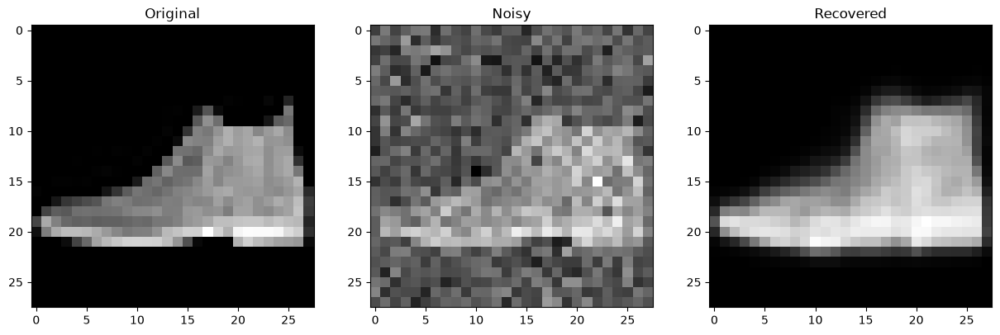

In [31]:
f, a = plt.subplots(1, 3, figsize=(15, 15)) #1행 3열의 표

# 시각화를 위해 넘파이 행렬로 바꿔줍니다.
original_img = np.reshape(original_x.to("cpu").data.numpy(), (28, 28))
noisy_img = np.reshape(noisy_x.to("cpu").data.numpy(), (28, 28))
recovered_img = np.reshape(recovered_x.to("cpu").data.numpy(), (28, 28))

# 원본 사진
a[0].set_title('Original')
a[0].imshow(original_img, cmap='gray')

# 오염된 원본 사진
a[1].set_title('Noisy')
a[1].imshow(noisy_img, cmap='gray')

# 복원된 사진
a[2].set_title('Recovered')
a[2].imshow(recovered_img, cmap='gray')

plt.show()

### 오토인코더의 종류

* **Tied weight Auto Encoder**

  ![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdBfh3m%2Fbtsl2IYkCHC%2FXsJij2oXygURbHbNgwRVK0%2Fimg.png)

  인코더의 weight matrix를 그대로 transpose하여 디코더의 weight matrix로 사용하는 구조

  학습할 weight가 절반밖에 안되서 계산속도가 빠르고 overfitting 위험이 적다


* **Denoising Auto Encoder**

  위에서 했던 오토인코더로 잡음 제거를 말함

  ![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbrvovM%2Fbtsl0KW9mLE%2FLauEk2qZY1eAvFkmjFKIWk%2Fimg.png)

  random 한 Gaussian noise를 input data에 추가하고, output으로는 noise-free 원본 데이터로 recover하도록 학습

  일반적인 AE와 target은 같은데, input이 다른 구조.

  AutoEncoder에 비해 Filter가 Edge를 더 잘 탐지하는 모습을 보여줌

* **Sparse Autoencoder**

  기본적인 Autoencoder 의 구조와는 다르게 Hidden layer 내의 Node 수가 더 많아진다.

  잠재 변수에서 활성화 되는 뉴런의 수를 제한하여, 모든 잠재 변수를 디코더가 참조하지 못하도록 강제하는 기법으로 sparse(0이 많은) 한 노드들을 만들고, 그 중에서 0과 가까운 값들은 전부 0으로 보내버리고 0 이 아닌값들만 사용하여 네트워크 학습을 진행한다.

  매번 학습이 될 때마다 활성화 되는 뉴런이 랜덤으로 바뀌면서, 디코더는 다른 조합의 잠재 변수를 참조하게 됨

  <img src = "https://lh3.googleusercontent.com/fife/AMPSemcinTSaS2SMj4KH8VE2XlECN1Ww0zQFwSnXUCfwk-j6-sfiLUFsHRfH-HHochiBj29RQdR6qdKbSxRFYOsy6s0AdK8SoMpAJ1DjiMOAxyCg8S4fo814zZuvHhPlnf_fuItdjT-tE6fEo1c4r4xSnqPKieQqiA7b62IIUdkkAjFq-s2NKYUqzr8JREAovKn1EmUsqx3H8H0FPFAc4OlQjbIttVI51TJXXHJakkAW3XoH-17x-xx92qJV685RIFEsru5GiN1aBGGOaTFEQVcGYOYHOPvjkygUt1Wqq3ksLEuzOW9psHVyQdBfwYVuDdh9yQcYZER9KeD1bwv35Rt-7IYN9Z-lBlOx2w6k3Bl4g4Dln5_7N2XGw3Ub9e7d8mPY0hipx525WBQh88XPzzoFMpO0ZaFXK-puBkeiKCg2Ng54BZa8KfSV_7X0W-fvEdCAbuqlOecDpsFFLW-L1kYq-4goiF0cPY5ebvNpBTI2enjtwfJzPJTxhW5fEbYjdFA8Y-dwPrBGqrGLPXbTbhhDNDvnvRRorGDy5oOLox0dCqH-4CEqP2eBBy6hKEqMEQ0mpcLqNFH9EXuPWmQkrkZQhj_NQCtQvmU7EsEmHWvAlveWcD-FqXr1pASnD96mI8z8hxwFKkancLZy1-3EIJCWZ_7-Exvt2ylP9FuqUPWJCXDcQMwUDfBPIscVyuXG9P8g0ACKLcby8h8Dzfzs_s3mi-Ia-fjtICXbR9hx-RVODewIRLLBkpzxA7Qp51KDMQwMycZp1aZG3tN2b5CMjYpyHRx8ns2AYhVjYBESndvQzr7Ud7h5YH54d9Fs-Ipu1EO5i3NbG0E0QOiJMp9_ygmsb4zATqr3FkjFPqMa1JTjj-TN8Vwva7FsDR3wiSx9lHe6nfYKvMANG5OA5fEH1jnCPJRTXq7Jn8fISwTAfZzqAPSGQRO5Iexow33sFGazeHx_uCaTAzUbTViTTjBNgM5ZJW_fh0u9ixGGQh66M6ooc8zcEAtnMrB4vEpz3CShedbkGjdO0GdO52vzy7C4ogSY2-IHrxkAssEvIU9VDy8hdVQMnOSH9AgTdDq3r8Qk0y5meoAJgCVEV69j8X6BQx67clLc2fhxFw7RVDFn_6RvvZEXpFWXOPE1G94Y-7-u8B0SxpE-LhQMS0TztOkvKtlfPbgbIFRSfn6fy1o4DHf8Aw9CJ-F4YNLxX_Ln5MJAEFo-8DdQpfqkFZ2cQyBD-35yrpaUvgexmEzlJkd8BhhJ384Wp9lSaMfURa9MqnCjsi6X6LK4hYZKxKt3FyQ2ckEPld6DvrkJoLd_Ne5ERo44-UoLu_0mZf1_f-Wk6xjjcntuUjinBABayVKu-6gA8xykAxjFVT_snh0argmInW8h5MWsc6herrFOxZsCk3kjZGkRnlyutmsLYy7M2HzG0eCKYbmRf6KhrjP1723IZj6VOl7TUHzqOnt7y8yEJkJ_APkCQjb4TpbAisBeN7X2KwMWFds" height = 300 width = 450>


* **Stacked Auto Encoder (Deep AE)**

  Layer를 늘려서 Deep하게 만들고,하나의 layer씩 분리해서 학습하는 구조의 모델

  Layer가 많으면 parameter가 많기 때문에 학습이 어렵고, dimension을 많이 줄이면 Reconstruction이 어렵다

  이러한 문제를 해결하기 위해 One-Layer AE 를 여러게 쌓아, 이전 AE에서 찾은 latent vector를 다음 AE의 Input으로 반복하는 방법으로 layer를 쌓는다
  
  최종 Stacked AE 에서는 직전 one-layer AE 에서 학습된 Weight들을 모아서 그대로 사용한다

  <img src = "https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fsk3fQ%2FbtqFANUD5Tc%2F8vXxtPWt8MeY26AXVJturk%2Fimg.png" height = 280 width = 250>
  <br/>
  <img src = "https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbOmL4W%2FbtqFzAa4Vv6%2FSip5BzE4kkELtxlhj2mkf1%2Fimg.png" height = 240 width = 240>
  <img src = "https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FkWOv4%2FbtqFzG9Z0zg%2Fv9UCtJqJ3lf382N48u9J7K%2Fimg.png" height = 240 width = 240>
  <img src = "https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fkxz3G%2FbtqFApTZViQ%2FblXV1GKwwO95hvRufMqPG0%2Fimg.png" height = 240 width = 240>
  <br/>
  <img src = "https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FHd6aY%2FbtqFBL9GjcG%2Fs0hjmlbM705Ny2d2AVHkx1%2Fimg.png" height = 280 width = 380>

  -> 이렇게 학습이 끝난 AutoEncoder로 weight를 Initialization해주고 모델의 학습을 위해 Backprop을 진행

  Stacked AE 의 대표적인 활용처는 Anomaly detection (이상탐지)이다. '이상'이라는 label 이 없는 데이터를 기준으로 S-AE를 구축하고, Reconstruction Error가 큰 데이터들을 이상치로 판단하는 개념

  ![](https://www.cognex.com/library/media/blogs/kr-deep-learning-research/autoencoder.jpg?la=ko-kr&hash=EAE518883DC308B296B9CE4F640A449960CFFF15&hash=EAE518883DC308B296B9CE4F640A449960CFFF15&sc_lang=ko-kr)

  * Classification task using Stacked Auto Encoder

    AE의 인코딩 부분까지만 자르고, 그 위에 Classification model 을 올려 feature extraction + prediction 모델을 결합

    학습된 인코더 부분의 weight 는 freeze 시키고, MLP부분의 weight만 따로 학습한 후 인코더의 뒷부분 wieght만 upper network와 추가적으로 재학습 (fine-tuning)

    ![이미지](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FckYmb5%2Fbtsl5ko7wjj%2FH2TkwkznrKkFVhDBShcUM0%2Fimg.png)


* **Convolution Auto Encoder**

    기본적인 오토인코더 구조는 동일하지만, CNN 처럼 convolution 필터를 이용한다

    ![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FduxCl7%2Fbtrul2OkluL%2FNPoba7cheVK4y7q89MsMk1%2Fimg.png)

    encoder에서는 convolution 연산을 수행하고 decoder부분에서는 transposed convolution 연산을 수행한다

    ![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F6JwuV%2FbtrubMlZmrH%2F2xHxTVDvr6MHXKdWzS64jK%2Fimg.png)

### Convolution Auto Encoder를 구현해보자

convolution을 위해 batch size를 바꿔주자

testdataset도 만들자

In [32]:
BATCH_SIZE = 32
# Fashion MNIST 데이터셋 불러오기
trainset = datasets.FashionMNIST(
    root      = './.data/',
    train     = True,
    download  = True,
    transform = transforms.ToTensor()
)
train_loader = torch.utils.data.DataLoader(
    dataset     = trainset,
    batch_size  = BATCH_SIZE,
    shuffle     = True,
    num_workers = 2
)

testset = datasets.FashionMNIST(
    root      = './.data/',
    train     = False,
    download  = True,
    transform = transforms.ToTensor()
)
test_loader = torch.utils.data.DataLoader(
    dataset     = testset,
    batch_size  = BATCH_SIZE,
    shuffle     = True,
    num_workers = 2
)

Convolution Auto Encoder 모듈 정의

In [33]:
class ConvolutionAutoencoder(nn.Module):
    def __init__(self):
        super(ConvolutionAutoencoder, self).__init__()

        self.encoder = nn.Sequential( # nn.Sequential을 사용해 encoder와 decoder 두 모듈로 묶어줍니다.
            nn.Conv2d(1,16,3,padding=1),                            # batch x 16 x 28 x 28
            nn.ReLU(),
            nn.BatchNorm2d(16),
            nn.Conv2d(16,32,3,padding=1),                           # batch x 32 x 28 x 28
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.Conv2d(32,64,3,padding=1),                           # batch x 32 x 28 x 28
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2,2),                                      # batch x 64 x 14 x 14
            nn.Conv2d(64,128,3,padding=1),                          # batch x 64 x 14 x 14
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,padding=1),                         # batch x 64 x 7 x 7
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256,128,3,2,1,1),                    # batch x 128 x 14 x 14
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.ConvTranspose2d(128,64,3,1,1),                       # batch x 64 x 14 x 14
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.ConvTranspose2d(64,16,3,1,1),                        # batch x 16 x 14 x 14
            nn.ReLU(),
            nn.BatchNorm2d(16),
            nn.ConvTranspose2d(16,1,3,2,1,1),                       # batch x 1 x 28 x 28
            nn.ReLU()
        )

    def forward(self, x):
        pre_encoded = self.encoder(x) # encoder는 encoded라는 잠재변수를 만들고
        encoded = pre_encoded.view(BATCH_SIZE, -1)
        decoded = self.decoder(pre_encoded) # decoder를 통해 decoded라는 복원이미지를 만듭니다.

        return encoded, decoded

In [34]:
cautoencoder = ConvolutionAutoencoder().to(DEVICE)

optimizer = torch.optim.Adam(cautoencoder.parameters(), lr=0.005)
# Adam()을 최적화함수로 사용합니다. Adam은 SGD의 변형함수이며 학습중인 기울기를 참고하여 학습 속도를 자동으로 변화시킵니다.
criterion = nn.MSELoss() #원본값과 디코더에서 나온 값의 차이를 계산하기 위해 평균제곱오차(Mean Squared Loss) 오차함수를 사용합니다.

In [35]:
#학습하기
for epoch in range(1, EPOCH+1):
    cautoencoder.train()
    for step, (x, label) in enumerate(train_loader):
        x = x.to(DEVICE)
        y = x.to(DEVICE) #x(입력)와 y(대상 레이블)모두 원본이미지(x)인 것을 주의해야 합니다.
        label = label.to(DEVICE)

        encoded, decoded = cautoencoder(x)

        loss = criterion(decoded, y) # decoded와 원본이미지(y) 사이의 평균제곱오차를 구합니다
        optimizer.zero_grad() #기울기에 대한 정보를 초기화합니다.
        loss.backward() # 기울기를 구합니다.
        optimizer.step() #최적화를 진행합니다.

torch.Size([32, 28, 28])


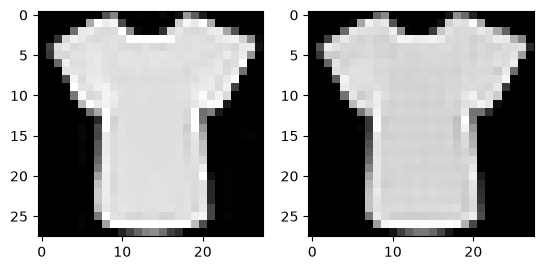

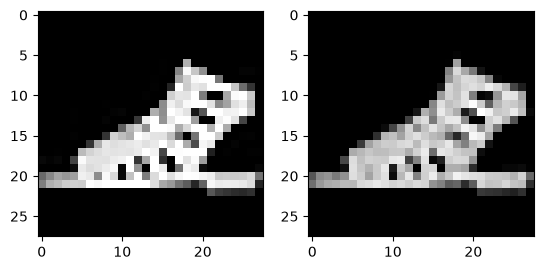

In [36]:
out_img = torch.squeeze(decoded.cpu().data)
print(out_img.size())

for i in range(2):
    plt.subplot(1,2,1)
    plt.imshow(torch.squeeze(x[i]).cpu().numpy(),cmap='gray')
    plt.subplot(1,2,2)
    plt.imshow(out_img[i].numpy(),cmap='gray')
    plt.show()

테스트 데이터 셋에서도 볼까?

In [37]:
with torch.no_grad():
    for step, (x, label) in enumerate(test_loader):

        x = x.to(DEVICE)
        encoded, decoded = cautoencoder(x)

torch.Size([16, 28, 28])


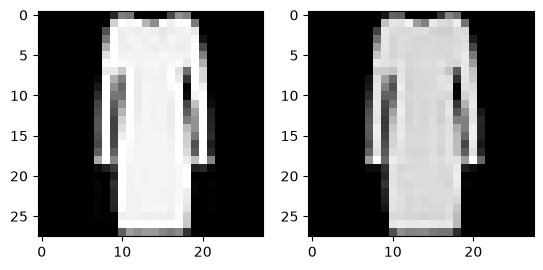

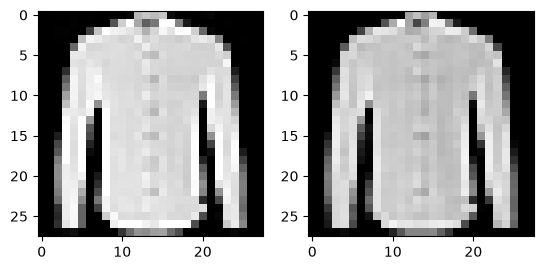

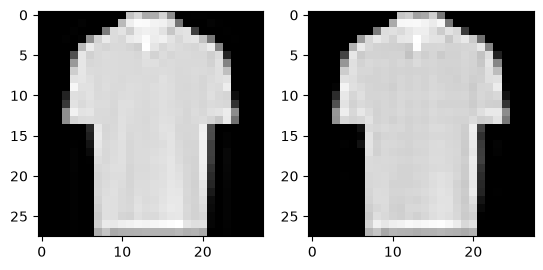

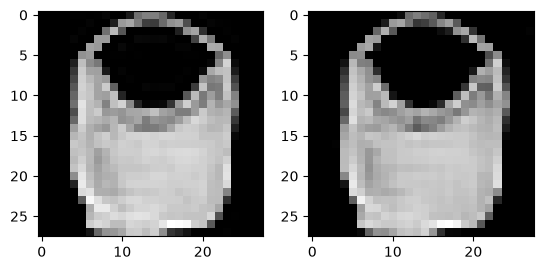

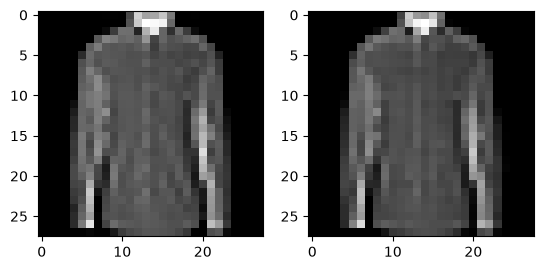

In [38]:
out_img = torch.squeeze(decoded.cpu().data)
print(out_img.size())

for i in range(5):
    plt.subplot(1,2,1)
    plt.imshow(torch.squeeze(x[i]).cpu().numpy(),cmap='gray')
    plt.subplot(1,2,2)
    plt.imshow(out_img[i].numpy(),cmap='gray')
    plt.show()

## VAE (Variational Autoencoder)

VAE는 생성 모델(Generative model)의 일종으로 이름은 오토인코더지만 AE와 VAE는 전혀 다른 모델이다

    참조 :: 생성모델이란?

    학습한 데이터를 바탕으로 실제로 있을 것 같은 데이터를 스스로 생성하는 모델
    생성모델의 목적 : 학습 데이터를 통해 학습 데이터가 존재하는 데이터 분포를 찾는 것

따라서 AE는 데이터의 특징을 추출하기 위해 encoder가 AI의 주체라면 VAE는 새로운 데이터를 생성하기 위해 decoder가 주체이다

VAE구조

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fb30Uzl%2FbtrxY4wKngj%2FSucVwitDrRtQvi1xTHdrR0%2Fimg.png)


* Encoder : input을 latent space로 변환
* Decoder : latent space를 input으로 변환하는 역할

### VAE를 이해하기 위한 수식들


생성하고자 하는 데이터와 우리가 학습하기 위해 가지고 있는 데이터 : x

모델의 파라미터$\theta$가 주어졌을 때 우리가 원하는 정답인 x가 나올 확률이 $P_\theta(x)$ 높을 수록 좋은 모델

x를 생성하기 위해 필요한 잠재 변수 : z

따라서 x를 잘 설명하는 feature를 추출하여 z에 담고, 이 z를 통해 x와 유사하지만 완전히 새로운 데이터를 생성하는 것이 목표

x의 주변확률 : $P(x) = \int P(x,z)dz$



> 참고 : 베이즈 이론
>
> $Bayes' theorem : P(x|z) = \frac{P(x,z)}{P(z)}$


▶ $P(x) = \int P(x,z)dz = \int P(z)P(x|z)dz$

<br/>

z의 분포에 대해 알고싶지만 z가 무수히 많을 뿐더러 이상적인 z가 존재하는 분포를 알 수 없다

→ 가지고 있는 x 데이터를 통해 z의 분포를 구하면 어떨까?

**== 변분 추론(Variational Inference)** : 복잡한 분포를 간단한 분포로 근사하는 것

직접적으로 $P(z)$를 구할 생각을 하지말고, x를 통해 z를 유추하는 $P(z|x)$를 구하자

<br/>

이상적인 $P(z|x)$를 알 수 없지만 간단한 정규분포 형태를 띠는 $Q(z)$를 가정

$P(z|x) \approx Q(z)$

<br/>

$P(z|x)$에 $Q(z)$를 잘 근사하기 위해 쿨백-라이블러 발산(Kullback-Leibler divergence, KLD)을 사용

> $kullback-Leibler divergence : $
>
> 두 분포의 차이를 계산하는 지표로서 두 분포가 비슷할수록 작은 값을, 두 분포가 다를수록 큰 값을 가짐
>
> $D_{KL}(P_1||P_2) = \sum P_1 log \frac{P_1}{P_2}$

$D_{KL}(Q(z)||P(z|x))$<br/>
$\overset{\underset{\mathrm{\Delta}}{}}{=}\sum_{z} Q(z)log \frac{Q(z)}{P(z|x)}$<br/>
$=\sum_{z} Q(z)log \frac{Q(z)P(x)}{P(z,x)} $<br/>
$=\sum_{z} Q(z)log \frac{Q(z)}{P(z,x)}+logP(x)\sum_{z}Q(z)$<br/>
$=\sum_{z} Q(z)log \frac{Q(z)}{P(x|z)P(z)}+logP(x)$<br/>
$=\sum_{z} Q(z)log \frac{Q(z)}{P(z)}-\sum_{z}Q(z)logP(x|z)+logP(x)$<br/>
> 확률변수의 함수 g(x)에 대한 기대값
>
> $\mathbb{E}[g(x)] = \sum_{x} g(x) \cdot f(x)$


$=D_{KL}(Q(z)||P(z))-\mathbb{E}_{z\sim Q(z)}[log P(x|z)]+logP(x)$<br/>
<br/>
$logP(x) = D_{KL}(Q(z)||P(z|x)) - D_{KL}(Q(z)||P(z))+\mathbb{E}_{z\sim Q(z)}[log P(x|z)]$<br/>
<br/>


▶$ELBO = -D_{KL}(Q(z)||P(z))+\mathbb{E}_{z\sim Q(z)}[log P(x|z)]$

결론 : $P(z)$→$P(z|x)$→ELBO(evidence lower bound)식


### ELBO와 Loss Function

$ELBO$<br/>
$ = -D_{KL}(Q(z)||P(z))+\mathbb{E}_{z\sim Q(z)}[log P(x|z)]$<br/>
$ = -D_{KL}(Q_\lambda(z|x)||P(z))+\mathbb{E}_{z\sim Q_\lambda(z|x)}[log P(x|z)]$<br/>
<br/>
$ELBO_i$<br/>
$ = -D_{KL}(Q_\lambda(z|x_i)||P(z))+\mathbb{E}_{z\sim Q_\lambda(z|x_i)}[log P(x_i|z)]$<br/>
<br/>
$loss_i = -ELBO_i$<br/>
$ = D_{KL}(Q_\lambda(z|x_i)||P(z))-\mathbb{E}_{z\sim Q_\lambda(z|x_i)}[log P(x_i|z)]$<br/>
<br/>
![](https://lh3.googleusercontent.com/fife/AMPSemfS510k1aQ8mgQ3EyhBEvSUuAgs9B2g_FFCGZ-Kpurd3hvP4t1kUdQ70XyeN-Mdgpwnkz3c19ziB5WsWT0KdokeXZus8kW36SAgHEFPmZdNgDSotoTZghdWD4iLSBuo14tJcr9P7MuSXb5ePLzgF0332aKHylguPMcA0rofUN6_zzHQnvWHJ3UvFoAeuzA9641V5DYynQJhnpr_z8KyBJ_HbjXV3mWNvTZmQmVfr8CRSHmqSVtTWWFmOcq0vp_rDS2A8vi2JkMZNCdfCcxl2X0ZIn4qvowdvhbjDJrSPgH2RFts9eUJUMgeAXwoqVl0VNiPGxco6m-EEhSpsfAcEzQHn0WJwlDjAWOHBgl96auAN7qUGNz5jcDUEKVIrW3KTUUtG0iGx9k_xqFLwE3qs9xI9kgseoO2KTAig5CKMVXxbnhRSjHkTO1M_C-qKSCZFeZsVaufp4wH2rxnHRPIxRT20hQCuAFcCOIjjU7kQdv7jHFZ9KRqZqY0c_3FH6yxP-iFyi7WtJlJwH1plf1icpoFlGigKzZ8A_u2tyWuNBDb67E5Vcppn2nJavB2Zhg5tJrRf58I3eek291x33sD1lzxHURP5lIaAgSqmv-ZS5942UfipBZQ6iPSY0hNL8Oc3vEfXpcAWtzdv4vLHSaT4EmZy9tx8aeR1-LY8LcX4jDceTvwDdwS3O2xjm0Ine1q2QO0V5_AQ0LTiiVrV6eA8ZfKoE56ea1f2YC_Qcb0UiayIZ3ISRbjz0jzphnQQhlNx32yoEmF6IiwfDVuLqN8mRcuVTg0h2oXpm37tLioCufUfRoo2Q3-OZqV_paN7ItfIHWj3TuC9kBroAIKNBQnYXUxX8FlwVy52Zl6rOZQceC-8WxNGejxEatrLGw5zb7xGWzvL-9bZOmG2aOw8Zpheb-j6_MVx0QVphWOmPAv8rBldEYLjziHWaU9CrOG7aN9dmn4mGb0F442kBZvfvOvDJVZIvxouqZZczSJ7GWn49jRJC6xb3m_Q3JsxmfrDdE2bBT9k4-GViHMh-5pqGNbA0URF9XXzl3lqoRBcUInMGmoIiuZNwxVLF9dAcPHYNt9I0oK5DnQtQOoafxYVTrpvP_6X23QC0RfLVAmgYaBrNsB87mEw-FUhfa0YbKPURVGAttr-QcS2gA9S7M-z4chBh_bXE9aH4f-C9hL2aKv2yceO10kfQE7jwN9EZCEovIN0Q7Y3v-nFBSl3KK2e0yf-I8ySsH9ThBX79O5pMFh73b6RtLZ26xjoceV48PoAOeTKEgdosycIIpsbEZHBObCQKWjB22Olx1TbweaNozcuto8c1DWKLV8E8KNcmdezOAxP8DOI_gzUbVZsOslChiCPY_akRVqAA_tNPFlUdDOdFl2M4fuwaL5tmjuH5K86D_b9J-8RtTytYCPhGAgb2mvDmRk6Sb5d8sGav2XWDUg_BFqzarRVL7d1zOxb07T0o6rHgkgzTHk0TfsViIP2gA7qAA)

* Regularization Term(encoder의 역할) : $Q_\lambda(z|x_i)$가 $P(z)$를 잘 근사해야 한다
* Reconstruction Term(decoder의 역할) : $P(x_i|z)$의 확률이 최대가 되어야 한다 = z를 통해 x를 잘 생성해야 한다


<br/>**최종 loss function**<br/>
$loss_i(\theta,\phi)= D_{KL}(Q_\theta(z|x_i)||P(z))-\mathbb{E}_{z\sim Q_\theta(z|x_i)}[log P_\phi(x_i|z)]$<br/>
<br/>


### Reparameterization Trick

최종으로 구한 loss function을 학습에 적용하기 위해 어떠한 가정이 들어가고 어떻게 코드로 풀어쓸 수 있는 지 알아보자

> 다변량 정규분포
>
> $N(\mu,\Sigma)$ : $\mu$는 nx1 행렬, $\Sigma$는 nxn 행렬

**regularization term**

$= D_{KL}(Q_\theta(z|x_i)||P(z))$<br/>

Encoder를 통해 나온 평균과 분산 값을 가지는 다변량 정규분포 $Q_\theta(z|x_i)$를 평균이 0, 분산이 1의 값을 가지는 다변량 정규분포 $P(z)$로 근사하자

두 개의 다변량 정규분포 KLD를 구하는 수식

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fd5UuY3%2FbtqZ2bbtPbF%2FdgvZ9xnlUyXgMhg9KqU7k0%2Fimg.png)

$=-\frac{1}{2}\sum_i(1+log\sigma_i^2-\mu_i^2-\sigma_i^2)$

<br/>

**reconstruction term**

$= -\mathbb{E}_{z\sim Q_\theta(z|x_i)}[log P_\phi(x_i|z)]$

expectation과 적분 정의에 따라 아래와 같이 다시 쓸 수 다

$=\int Q_\theta(z|x_i)log P_\phi(x_i|z)dz$<br/>

> Monte Carlo Estimation 기법
>
> 무작위로 대량의 데이터를 추출하여 함수의 값을 수리적으로 근사하는 방법
>
> 모든 z를 고려하는 대신에 충분히 많은 $z_1$, $z_2$, ..., $z_n$을 뽑아서 값을 구하고 평균값을 사용하면 전체 z의 효과를 낼 수 있다

$\approx \frac{1}{n}\sum_{j=1}^n log P_\phi(x_i|z_j)$<br/>

n개의 z를 sampling 하지 말고 하나의 z만 sampling하여 사용

$=log P_\phi (x_i|z)$

이제 문제는 z를 sampling 하는 과정에서 미분이 불가능하다는 문제(매번 z가 랜덤샘플링 되기 때문)

평균이 0, 분산이 1인 다변량 정규분포에 noise를 샘플링한 후 이를 인코더에서 구한 평균과 분산을 이용하여 더하고 곱해서 사용

$z = \mu + \epsilon \cdot \sigma$

이렇게 z를 정의하면

$log P_\phi (x_i|z)$

> 베르누이 분포
>
> $P(X=x) = p^x \cdot (1-p)^{1-x}$

디코더가 베르누이 분포를 따른다고 가정

$=log(x'_i)^{x_i}(1-x'_i)^{1-x_i}$

$=x_ilogx'_i+(1-x_i)log(1-x'_i)$

> binary cross entropy
>
> $BCE Loss(ŷ,y) = -(y ⋅ log ŷ + (1-y) ⋅ log(1-ŷ))$

-> binary cross entropy loss function 사용

-> F.binary_cross_entropy()로 사용할 수 있다

### VAE를 파이토치로 구현해보자

(https://cumulu-s.tistory.com/25)

필요한 패키지들을 불러오자

이번에는 텐서보드로 손실함수도 보자

In [39]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm
from torch.nn import functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter
import datetime
import os
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'tensorboard'

In [ ]:
!pwd

/content


In [ ]:
USE_CUDA = torch.cuda.is_available()
DEVICE = torch.device("cuda" if USE_CUDA else "cpu")
print("사용하는 Device : ", DEVICE)

current_time = datetime.datetime.now() + datetime.timedelta(hours= 9) #Google Colab의 경우 한국 시간보다 9시간 느리기 때문에 9시간을 더함
current_time = current_time.strftime('%Y-%m-%d-%H:%M')

#tensorboard를 사용하면, 코드가 돌아가면서 loss나 이미지가 찍히는데
#이를 돌릴때마다 결과를 나눠서 가지고 있어야 하기 때문에 폴더를 별도로 만듬
os.mkdir('/content/VAE_Result')
saved_loc = os.path.join('/content/VAE_Result', current_time)
os.mkdir(saved_loc)

print("저장 위치: ", saved_loc)

writer = SummaryWriter(saved_loc) #텐서보드를 써주는 객체
EPOCHS = 50
BATCH_SIZE = 200

사용하는 Device :  cuda
저장 위치:  /content/VAE_Result/2023-09-13-10:58


MNIST 데이터를 불러와주자

In [ ]:
# Transformer code
transformer = transforms.Compose([
            transforms.ToTensor()
])


# Loading trainset, testset and trainloader, testloader
trainset = torchvision.datasets.MNIST(root = '/content/MNIST', train = True,
                                        download = True, transform = transformer)

trainloader = torch.utils.data.DataLoader(trainset, batch_size = BATCH_SIZE, shuffle = True, num_workers = 2)


testset = torchvision.datasets.MNIST(root = '/content/MNIST', train = False,
                                        download = True, transform = transformer)

testloader = torch.utils.data.DataLoader(testset, batch_size = BATCH_SIZE, shuffle = True, num_workers = 2)

100%|██████████| 9912422/9912422 [00:00<00:00, 129459661.10it/s]


Extracting /content/MNIST/MNIST/raw/train-images-idx3-ubyte.gz to /content/MNIST/MNIST/raw



100%|██████████| 28881/28881 [00:00<00:00, 17785302.28it/s]


Extracting /content/MNIST/MNIST/raw/train-labels-idx1-ubyte.gz to /content/MNIST/MNIST/raw



100%|██████████| 1648877/1648877 [00:00<00:00, 53777061.16it/s]

Extracting /content/MNIST/MNIST/raw/t10k-images-idx3-ubyte.gz to /content/MNIST/MNIST/raw



100%|██████████| 4542/4542 [00:00<00:00, 1900491.70it/s]


Extracting /content/MNIST/MNIST/raw/t10k-labels-idx1-ubyte.gz to /content/MNIST/MNIST/raw



8개의 이미지만 출력해보자

<class 'torch.Tensor'>
torch.Size([3, 32, 242])


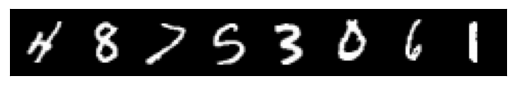

In [ ]:
# sample check
sample, label = next(iter(trainloader))

# show grid image
def imshow_grid(img):
    img = torchvision.utils.make_grid(img)
    print(type(img))
    print(img.shape)
    plt.imshow(img.permute(1, 2, 0))
    ax = plt.gca()
    ax.axes.xaxis.set_visible(False)
    ax.axes.yaxis.set_visible(False)
    plt.show()


imshow_grid(sample[0:8])

핵심이 되는 VAE 모델 코드는 아래와 같다

**encode**

$p_\phi(z|x)$인 Encoder는 이미지를 받아서 $\mu$와 $\sigma$를 출력해야 한다

fc1 → relu → fc2 → relu 한 후에 latent space 차원만큼 $\mu$와 $\sigma$를 출력한다

**reparameterization**

$\mu$와 $\sigma$가 주어졌을 때, latent variable z를 만드는 함수

logvar인 이유는 표준편차 값이 음수가 되지 않도록 만들기 위해서, encoder에서 나온 self.fc32의 결괏값을 $log \sigma ^2$으로 생각한다

$\sigma = e^{log\sigma} = e^{\frac{2log\sigma}{2}} = e^{\frac{log \sigma^2}{2}} = e^{\frac{logvar}{2}}$

std = torch.exp(0.5 * logvar)

    torch.randn_like : 평균이 0, 분산이 1인 정규분포에서 숫자를 뽑아 tensor를 만들어줌

eps = torch.randn_like(std)

출력값 z = mu + std * eps

**decode**

z를 받아 fc4 → relu →fc5 → relu → fc6 → sigmoid하여 이미지 사이즈와 동일한 차원을 가진 0~1사이의 값으로 출력

In [ ]:
# VAE model
class VAE(nn.Module):
    def __init__(self, image_size, hidden_size_1, hidden_size_2, latent_size):
        super(VAE, self).__init__()

        self.fc1 = nn.Linear(image_size, hidden_size_1)
        self.fc2 = nn.Linear(hidden_size_1, hidden_size_2)
        self.fc31 = nn.Linear(hidden_size_2, latent_size)
        self.fc32 = nn.Linear(hidden_size_2, latent_size)

        self.fc4 = nn.Linear(latent_size, hidden_size_2)
        self.fc5 = nn.Linear(hidden_size_2, hidden_size_1)
        self.fc6 = nn.Linear(hidden_size_1, image_size)

    def encode(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        return self.fc31(h2), self.fc32(h2)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        h3 = F.relu(self.fc4(z))
        h4 = F.relu(self.fc5(h3))
        return torch.sigmoid(self.fc6(h4))

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, 784))
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

모델과 optimizer 정의

In [ ]:
VAE_model = VAE(28*28, 512, 256, 2).to(DEVICE)
optimizer = optim.Adam(VAE_model.parameters(), lr = 1e-3)

손실함수 정의! 이걸 위해 위에서 어려운 수식을 배웠죠

In [ ]:
def loss_function(recon_x, x, mu, logvar):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction = 'sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return BCE, KLD

In [ ]:
def train(epoch, model, train_loader, optimizer):
    model.train()
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(DEVICE)
        optimizer.zero_grad()

        recon_batch, mu, logvar = model(data)

        BCE, KLD = loss_function(recon_batch, data, mu, logvar)

        loss = BCE + KLD

        writer.add_scalar("Train/Reconstruction Error", BCE.item() / len(data), batch_idx + epoch * (len(train_loader.dataset)/BATCH_SIZE) )
        writer.add_scalar("Train/KL-Divergence", KLD.item() / len(data), batch_idx + epoch * (len(train_loader.dataset)/BATCH_SIZE) )
        writer.add_scalar("Train/Total Loss" , loss.item() / len(data), batch_idx + epoch * (len(train_loader.dataset)/BATCH_SIZE) )

        loss.backward()

        train_loss += loss.item()

        optimizer.step()

        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\t Loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader),
                loss.item() / len(data)))

    print("======> Epoch: {} Average loss: {:.4f}".format(
        epoch, train_loss / len(train_loader.dataset)
    ))

In [ ]:
def test(epoch, model, test_loader):
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for batch_idx, (data, _) in enumerate(test_loader):
            data = data.to(DEVICE)

            recon_batch, mu, logvar = model(data)
            BCE, KLD = loss_function(recon_batch, data, mu, logvar)

            loss = BCE + KLD

            writer.add_scalar("Test/Reconstruction Error", BCE.item() / len(data), batch_idx + epoch * (len(test_loader.dataset)/BATCH_SIZE) )
            writer.add_scalar("Test/KL-Divergence", KLD.item() / len(data), batch_idx + epoch * (len(test_loader.dataset)/BATCH_SIZE) )
            writer.add_scalar("Test/Total Loss" , loss.item() / len(data), batch_idx + epoch * (len(test_loader.dataset)/BATCH_SIZE) )
            test_loss += loss.item()

            if batch_idx == 0:
                n = min(data.size(0), 8)
                comparison = torch.cat([data[:n], recon_batch.view(BATCH_SIZE, 1, 28, 28)[:n]]) # (16, 1, 28, 28)
                grid = torchvision.utils.make_grid(comparison.cpu()) # (3, 62, 242)
                writer.add_image("Test image - Above: Real data, below: reconstruction data", grid, epoch)

요거는 latent를 이미지로 만드는 코드

In [ ]:
def latent_to_image(epoch, model):
    with torch.no_grad():
        sample = torch.randn(64, 2).to(DEVICE)
        recon_image = model.decode(sample).cpu()
        grid = torchvision.utils.make_grid(recon_image.view(64, 1, 28, 28))
        writer.add_image("Latent To Image", grid, epoch)

In [ ]:
for epoch in tqdm(range(0, EPOCHS)):
    train(epoch, VAE_model, trainloader, optimizer)
    test(epoch, VAE_model, testloader)
    print("\n")
    latent_to_image(epoch, VAE_model)

writer.close()

  0%|          | 0/50 [00:00<?, ?it/s]

Train Epoch: 0 [0/60000 (0%)]	 Loss: 543.482891
Train Epoch: 0 [20000/60000 (33%)]	 Loss: 189.705312
Train Epoch: 0 [40000/60000 (67%)]	 Loss: 174.719121
======> Epoch: 0 Average loss: 191.7455


Train Epoch: 1 [0/60000 (0%)]	 Loss: 167.306426
Train Epoch: 1 [20000/60000 (33%)]	 Loss: 165.791895
Train Epoch: 1 [40000/60000 (67%)]	 Loss: 158.600947
======> Epoch: 1 Average loss: 161.2868


Train Epoch: 2 [0/60000 (0%)]	 Loss: 157.695518
Train Epoch: 2 [20000/60000 (33%)]	 Loss: 156.457090
Train Epoch: 2 [40000/60000 (67%)]	 Loss: 154.999883
======> Epoch: 2 Average loss: 156.7090


Train Epoch: 3 [0/60000 (0%)]	 Loss: 159.750771
Train Epoch: 3 [20000/60000 (33%)]	 Loss: 150.495801
Train Epoch: 3 [40000/60000 (67%)]	 Loss: 156.719580
======> Epoch: 3 Average loss: 153.9181


Train Epoch: 4 [0/60000 (0%)]	 Loss: 152.708008
Train Epoch: 4 [20000/60000 (33%)]	 Loss: 155.959395
Train Epoch: 4 [40000/60000 (67%)]	 Loss: 150.332383
======> Epoch: 4 Average loss: 151.7332


Train Epoch: 5 [0/60

Total Loss = KL-Divergence + Reconstruction Error로 계산

Reconstruction Error는 감소, KL-Divergence는 증가하여 Total loss는 감소

Reconstruction Error가 감소하는 것을 볼 때, 기존 이미지를 잘 구현해내는 것을 알 수 있으나 KL-Divergence가 계속해서 증가하는 걸로 보아 $q_\phi(z|x^i)$가 $p_\theta(z)$와 가까워지지 못하고 있음

Encoder의 parameter들이 적절하게 학습되지 못하고 있음

In [ ]:
%load_ext tensorboard

%tensorboard --logdir='/content/VAE_Result/2023-09-13-10:58'

<IPython.core.display.Javascript object>

학습된 VAE로 만들어진 10000개의 MNIST 테스트 이미지의 2D 표현

In [ ]:
testloader_2 = torch.utils.data.DataLoader(testset, batch_size = 10000, shuffle = True, num_workers = 2)

(10000, 2)


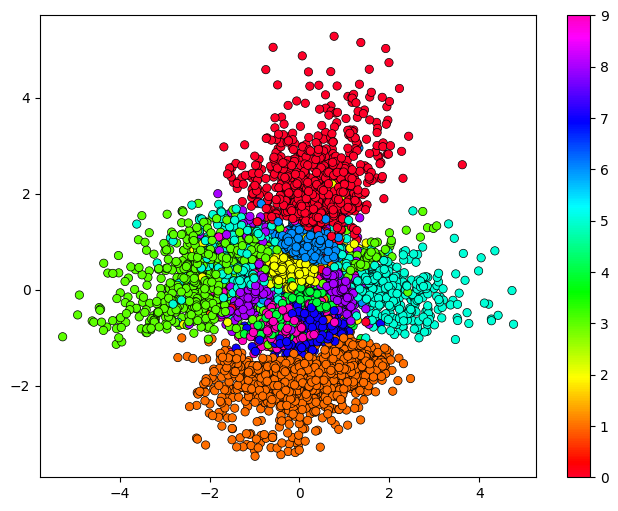

In [ ]:
sample, label = next(iter(testloader_2))
label_np = label.numpy() # For plotting

mu, _ = VAE_model.encode(sample.view(-1, 784).to(DEVICE))
mu = mu.cpu().detach().numpy()
print(mu.shape)
plt.figure(figsize = (8, 6))
plt.scatter(mu[:, 0], mu[:, 1], c = label_np, cmap = 'gist_rainbow', edgecolors = 'black', linewidth = 0.5)
plt.colorbar()

(x_value, y_value)의 변화에 따른 Decoded image의 변화 추이를 살펴보기

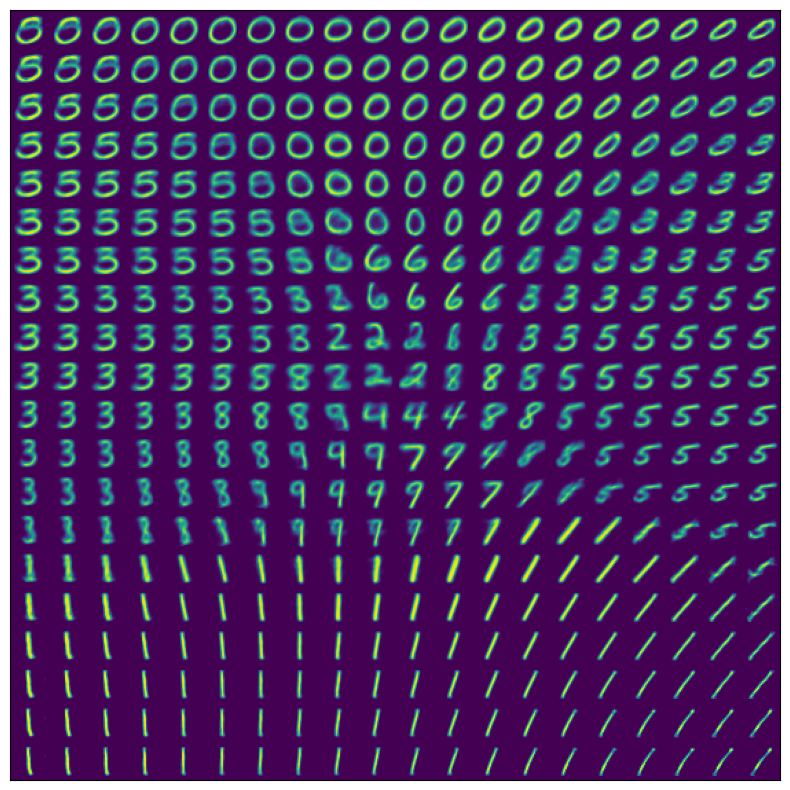

In [ ]:
nx = ny = 20
x_values = np.linspace(-3, 3, nx) # -3부터 3까지 균등한 간격으로 숫자 만들기
y_values = np.linspace(-3, 3, ny) # -3부터 3까지 균등한 간격으로 숫자 만들기

canvas = np.empty((28*ny, 28*nx)) # (560, 560)짜리 np.array 만들기
for i, yi in enumerate(x_values): # 20번 for loop 돌게됨
    for j, xi in enumerate(y_values): # 20번 for loop 돌게됨
        z_mu = np.array([[xi, yi]*100]).reshape(100,2) # [xi, yi]로 구성된 (100, 2) 짜리 np.array를 생성
        x_mean = VAE_model.decode(torch.Tensor(z_mu).to(DEVICE)) # Decoding => (100, 784)
        canvas[(nx-i-1)*28:(nx-i)*28, j*28:(j+1)*28] = x_mean[0].cpu().detach().reshape(28, 28)

plt.figure(figsize=(8, 10))
#Xi, Yi = np.meshgrid(x_values, y_values)
plt.imshow(canvas, origin="upper")
ax = plt.gca()
ax.axes.xaxis.set_visible(False)
ax.axes.yaxis.set_visible(False)
plt.tight_layout()

## FCN vs UNET



### Segmentation이란?

이미지의 픽셀 수준에서 각 영역이 어떤 의미를 갖는지 분리하는 방법

* Semantic Segmentation : 의미 대로 image 분할
* Instance Segmentation : object 대로 사진 분할

![](https://velog.velcdn.com/images%2Fcha-suyeon%2Fpost%2Faa245159-a1f4-47f3-8e30-4f48ec916543%2Fimage.png)

의미 대로 이미지를 분할 한다?

구체적으로는 이미지의 각 픽셀이 어느 클래스에 속하는지 예측하는 것!!

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FoXhHC%2Fbtq0vRbGj1m%2FKX1XtTC3F0DM7pOb906QYK%2Fimg.png)

Sementic Segmentation의 목적

*사진에 있는 모든 픽셀을, 해당하는 class로 분류하는 것*


### FCN (Fully-Convolution Network)

FCN은 LeNet과 같은 초기 CNN 모델이 Semantic Segmentation 문제에서 좋은 성능을 보이지 못하는 한계를 극복하기 위해 제안된 모델이다

따라서 기존 CNN모델(AlexNet, GoogLeNet)을 목적에 맞춰 변형시킨 형태

![](https://gaussian37.github.io/assets/img/vision/segmentation/fcn/1.png)

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fdab59q%2Fbtq0tfkffFq%2Fk4GD8TKLusWjfVq36DMBn0%2Fimg.png)

네 가지 단계가 존재

1.   Convolution Layer를 통해 Feature 추출
2.   1 x 1 Convolution Layer를 통해, 낮은 해상도의 Class Presence Heat Map 추출
3.   Transposed Convolution 을 통해서, 낮은 해상도의 Heat Map을 Upsampling 한 뒤, 인풋과 같은 크기의 Map 생성
4.   Map의 각 pixel class에 따라 색칠 한 뒤, Segmentation 결과 반환 = 각 픽셀당 확률이 가장 높은 클래스를 선정

### Upsampling 방법

Upsampling을 할 때 1/32로 줄어든 특성맵을 한번에 32배 만큼 늘리면 아래와 같이 많이 뭉뚱그려져 있고 디테일이 없어짐

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FZHivi%2Fbtq0qA3fGBE%2FsDELHesscgPxC2cbWk6au1%2Fimg.png)
![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fbb7uvh%2Fbtq0zdkIsTF%2FQWkZ87uNnbUqjb505VldH0%2Fimg.png)


**skip combining** 기법 사용

컨볼루션과 풀링 단계로 이루어진 이전 단계의 컨볼루션층들의 특성맵을 참고하여 upsampling

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FZTyVe%2Fbtq0vPLEa9K%2FyDo9ZkXqPknWkXPIEImWK1%2Fimg.png)

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FcExu63%2Fbtq0u5OM1rP%2FQp8uJPTBpkMC0xkZoqJzAK%2Fimg.png)


결과

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FczpfKI%2Fbtq0vPkz77r%2F9vhp9EICvkrgtKTPrUtTM0%2Fimg.png)








파이토치에 있는 FCN을 한 번 사용해볼까?

In [ ]:
import torch
model = torch.hub.load('pytorch/vision:v0.10.0', 'fcn_resnet50', pretrained=True)
# or
# model = torch.hub.load('pytorch/vision:v0.10.0', 'fcn_resnet101', pretrained=True)
model.eval()

Downloading: "https://github.com/pytorch/vision/zipball/v0.10.0" to /root/.cache/torch/hub/v0.10.0.zip
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FCN_ResNet50_Weights.COCO_WITH_VOC_LABELS_V1`. You can also use `weights=FCN_ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/fcn_resnet50_coco-1167a1af.pth" to /root/.cache/torch/hub/checkpoints/fcn_resnet50_coco-1167a1af.pth
100%|██████████| 135M/135M [00:00<00:00, 227MB/s]


FCN(
  (backbone): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequenti

사용할 데이터를 다운받아 오기

In [ ]:
import urllib
url, filename = ("https://github.com/pytorch/hub/raw/master/images/deeplab1.png", "deeplab1.png")
try: urllib.URLopener().retrieve(url, filename)
except: urllib.request.urlretrieve(url, filename)

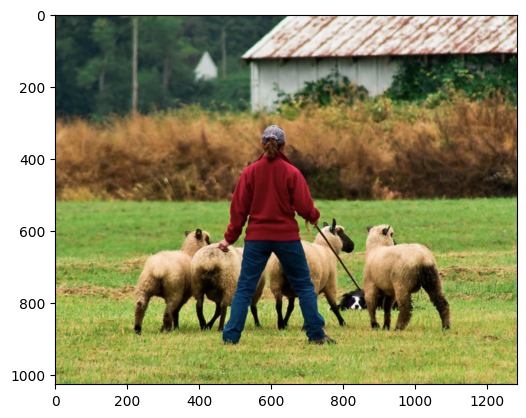

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
input_image = Image.open(filename)
input_image = input_image.convert("RGB")
plt.imshow(input_image)

In [ ]:
# sample execution (requires torchvision)
from torchvision import transforms
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

input_tensor = preprocess(input_image)
input_batch = input_tensor.unsqueeze(0) # create a mini-batch as expected by the model

# move the input and model to GPU for speed if available
if torch.cuda.is_available():
    input_batch = input_batch.to('cuda')
    model.to('cuda')

with torch.no_grad():
    output = model(input_batch)['out'][0]
output_predictions = output.argmax(0)

결과를 그려보자

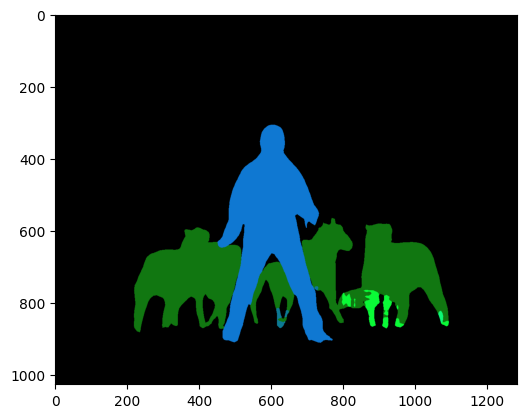

In [ ]:
# create a color pallette, selecting a color for each class
palette = torch.tensor([2 ** 25 - 1, 2 ** 15 - 1, 2 ** 21 - 1])
colors = torch.as_tensor([i for i in range(21)])[:, None] * palette
colors = (colors % 255).numpy().astype("uint8")

# plot the semantic segmentation predictions of 21 classes in each color
r = Image.fromarray(output_predictions.byte().cpu().numpy()).resize(input_image.size)
r.putpalette(colors)

plt.imshow(r)
# plt.show()

### VGG를 기반으로 하는 FCN 구현해보자

kaggle에서 제공하는 Chest X-ray를 사용하여 폐 영역을 segmentation해보자

(https://kimbg.tistory.com/18)

In [ ]:
!pip install -q kaggle

In [ ]:
! mkdir -p ~/.kaggle

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
! cp kaggle.json ~/.kaggle/

In [ ]:
! chmod 600 /root/.kaggle/kaggle.json

In [ ]:
! kaggle datasets download -d nikhilpandey360/chest-xray-masks-and-labels

100% 9.56G/9.58G [03:43<00:00, 54.9MB/s]
100% 9.58G/9.58G [03:43<00:00, 46.1MB/s]


In [ ]:
! unzip -q /content/chest-xray-masks-and-labels

In [ ]:
import time
import torch
import torch.nn as nn
import torchvision as tv
from torchvision import models
from torchsummary import summary as model_summary
from sklearn import model_selection

In [ ]:
### HYPER PARAMETER ###
RANDOM_SEED = 831
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 4
NUM_CLASS = 2
EPOCHS = 10

TEST_ratio = 0.1
VAL_ratio = 0.2

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

root_path = '/content/Lung Segmentation'

CXR_path = os.path.join(root_path, 'CXR_png')
MASK_path = os.path.join(root_path, 'masks')

In [ ]:
CXR_list = sorted(os.listdir(CXR_path))
MASK_list = sorted(os.listdir(MASK_path))
MASK_list_ = list(map(lambda x:x.split('.')[0][:-5]+'.png', MASK_list))
CXR_MASK_union_list = set(MASK_list_) & set(CXR_list)
CXR_path_list = sorted(list(map(lambda x:os.path.join(root_path, 'CXR_png', x), CXR_MASK_union_list)))
MASK_path_list = sorted(list(map(lambda x:os.path.join(root_path, 'masks', x.split('.')[0]+'_mask.png'), CXR_MASK_union_list)))
print(len(CXR_path_list), CXR_path_list[:1])
print(len(MASK_path_list), MASK_path_list[:1])

X, X_test, y, y_test = model_selection.train_test_split(CXR_path_list, MASK_path_list, test_size=TEST_ratio, random_state=RANDOM_SEED)
X_train, X_val, y_train, y_val = model_selection.train_test_split(X, y, test_size=VAL_ratio, random_state=RANDOM_SEED)
print(len(X_train), len(X_val), len(X_test))

samplex = tv.io.read_image(X_train[0])
sampley = tv.io.read_image(y_train[0])
print(samplex.shape, samplex.dtype)
print(sampley.shape, sampley.dtype, np.unique(sampley))

566 ['/content/Lung Segmentation/CXR_png/CHNCXR_0001_0.png']
566 ['/content/Lung Segmentation/masks/CHNCXR_0001_0_mask.png']
407 102 57
torch.Size([1, 2946, 2994]) torch.uint8
torch.Size([1, 2946, 2994]) torch.uint8 [  0 255]


In [ ]:
### DATA LOADER ###
class MyDataLoader(torch.utils.data.Dataset):

    def __init__(self, img_path, img_labels, transforms_x=None, transforms_y=None):
        self.img_path = img_path
        self.img_labels = img_labels
        self.transforms_x = transforms_x
        self.transforms_y = transforms_y

    def __len__(self):
        return len(self.img_path)

    def __getitem__(self, index):
        ten_x = tv.io.read_image(self.img_path[index])/255
        if ten_x.shape[0] == 3:
            ten_x = ten_x[:1]

        ten_y = tv.io.read_image(self.img_labels[index]).to(torch.int64)
        ten_y = ten_y.squeeze(dim=0)
        tenoh_y = OneHotEncoding(ten_y, num_classes=NUM_CLASS)

        if self.transforms_x:
            ten_x = self.transforms_x(ten_x)
        if self.transforms_y:
            tenoh_y = self.transforms_y(tenoh_y)

        ten_x = ten_x[0]
        ten_x = torch.stack([ten_x,ten_x,ten_x], dim=0)
        return ten_x, tenoh_y


def OneHotEncoding(labels, num_classes:int):
    shape = labels.shape
    label_oh = torch.zeros(*shape)
    for cnt, i in enumerate(sorted(np.unique(labels))):
        i_mask = torch.where(labels == i, cnt, 0)
        label_oh.masked_fill_(i_mask, cnt)
    label_oh = F.one_hot(label_oh.to(torch.int64), num_classes=num_classes)
    label_oh = label_oh.permute(2,0,1).to(torch.float)
    return label_oh


### TRANSFORM & CHECK ###
train_x_transforms = tv.transforms.Compose([
    tv.transforms.Resize(size=IMAGE_SIZE),
     ])
train_y_transforms = tv.transforms.Compose([
    tv.transforms.Resize(size=IMAGE_SIZE, interpolation=tv.transforms.InterpolationMode.NEAREST),
     ])

val_x_transforms = tv.transforms.Compose([
    tv.transforms.Resize(size=IMAGE_SIZE),
     ])
val_y_transforms = tv.transforms.Compose([
    tv.transforms.Resize(size=IMAGE_SIZE, interpolation=tv.transforms.InterpolationMode.NEAREST),
     ])

In [ ]:
train_ds = MyDataLoader(X_train, y_train,
                        transforms_x=train_x_transforms, transforms_y=train_y_transforms)
val_ds = MyDataLoader(X_val, y_val,
                      transforms_x=val_x_transforms, transforms_y=val_y_transforms)
test_ds = MyDataLoader(X_test, y_test,
                      transforms_x=val_x_transforms, transforms_y=val_y_transforms)

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=0)

train_sample_x, train_sample_y = next(iter(train_loader))
print(f'train_sample_x.shape: {train_sample_x.shape}')
print(f'train_sample_x.dtpye: {train_sample_x.dtype}')
print(f'train_sample_x.min, max: {torch.min(train_sample_x), torch.max(train_sample_x)}')
print(f'train_sample_y.shape: {train_sample_y.shape}')
print(f'train_sample_y.dtpye: {train_sample_y.dtype}')
print(f'train_sample_y.min, max: {torch.min(train_sample_y), torch.max(train_sample_y)}')
print(f'train_sample_y.unique: {np.unique(train_sample_y)}')

/usr/local/lib/python3.10/dist-packages/torchvision/transforms/functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


train_sample_x.shape: torch.Size([4, 3, 224, 224])
train_sample_x.dtpye: torch.float32
train_sample_x.min, max: (tensor(0.), tensor(1.))
train_sample_y.shape: torch.Size([4, 2, 224, 224])
train_sample_y.dtpye: torch.float32
train_sample_y.min, max: (tensor(0.), tensor(1.))
train_sample_y.unique: [0. 1.]


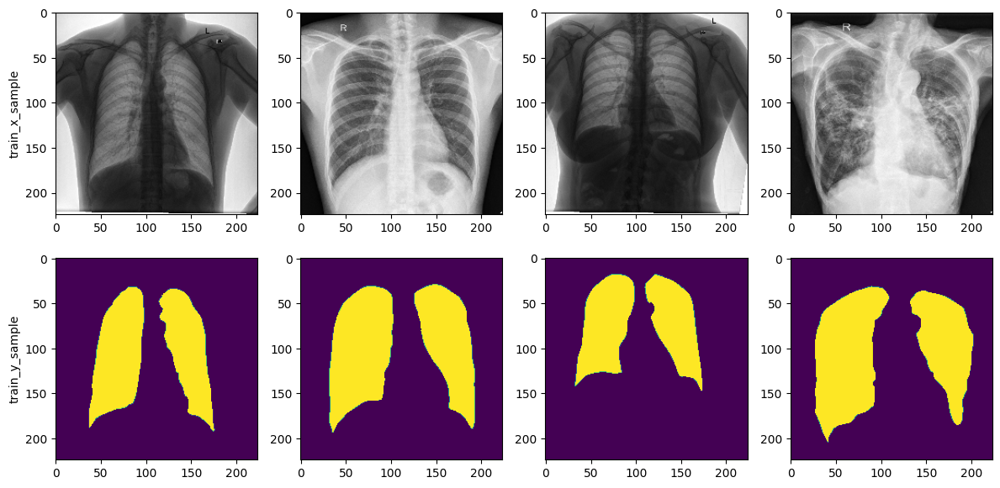

In [ ]:
### VISUALIZE ###
ncols, nrows = 4, 2
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3*ncols, 3*nrows))
for i in range(ncols):
    img0 = train_sample_x[i].permute(1,2,0)
    img1 = train_sample_y[i].permute(1,2,0)[:,:,-1]

    axes[0,i].imshow(img0)
    axes[0,0].set_ylabel('train_x_sample')

    axes[1,i].imshow(img1)
    axes[1,0].set_ylabel('train_y_sample')
plt.tight_layout()
plt.show()
###################################################

직관적으로 구현한 코드로 torchvision에서 제공하는 pretrained VGG를 활용하는 방법도 있다!

본 코드는 모든 maxpooling layer를 output으로 활용

In [ ]:
class FCN(nn.Module):
    def __init__(self):
        super(FCN, self).__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block5 = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.relu    = nn.ReLU(inplace=True)
        self.deconv1 = nn.ConvTranspose2d(512, 512, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn1     = nn.BatchNorm2d(512)
        self.deconv2 = nn.ConvTranspose2d(512, 256, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn2     = nn.BatchNorm2d(256)
        self.deconv3 = nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn3     = nn.BatchNorm2d(128)
        self.deconv4 = nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn4     = nn.BatchNorm2d(64)
        self.deconv5 = nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn5     = nn.BatchNorm2d(32)
        self.classifier = nn.Conv2d(32, 2, kernel_size=1)

    def forward(self, x):
        x = self.block1(x)
        x1 = x
        x = self.block2(x)
        x2 = x
        x = self.block3(x)
        x3 = x
        x = self.block4(x)
        x4 = x
        x = self.block5(x)
        x5 = x

        score = self.bn1(self.relu(self.deconv1(x5)))     # size=(N, 512, x.H/16, x.W/16)
        score = score + x4                                # element-wise add, size=(N, 512, x.H/16, x.W/16)
        score = self.bn2(self.relu(self.deconv2(score)))  # size=(N, 256, x.H/8, x.W/8)
        score = score + x3                                # element-wise add, size=(N, 256, x.H/8, x.W/8)
        score = self.bn3(self.relu(self.deconv3(score)))  # size=(N, 128, x.H/4, x.W/4)
        score = score + x2                                # element-wise add, size=(N, 128, x.H/4, x.W/4)
        score = self.bn4(self.relu(self.deconv4(score)))  # size=(N, 64, x.H/2, x.W/2)
        score = score + x1                                # element-wise add, size=(N, 64, x.H/2, x.W/2)
        score = self.bn5(self.relu(self.deconv5(score)))  # size=(N, 32, x.H, x.W)
        score = self.classifier(score)                    # size=(N, n_class, x.H/1, x.W/1)

        return score

model = FCN()
model_summary(model, (3,224,224), device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 224, 224]           1,792
              ReLU-2         [-1, 64, 224, 224]               0
            Conv2d-3         [-1, 64, 224, 224]          36,928
              ReLU-4         [-1, 64, 224, 224]               0
         MaxPool2d-5         [-1, 64, 112, 112]               0
            Conv2d-6        [-1, 128, 112, 112]          73,856
              ReLU-7        [-1, 128, 112, 112]               0
            Conv2d-8        [-1, 128, 112, 112]         147,584
              ReLU-9        [-1, 128, 112, 112]               0
        MaxPool2d-10          [-1, 128, 56, 56]               0
           Conv2d-11          [-1, 256, 56, 56]         295,168
             ReLU-12          [-1, 256, 56, 56]               0
           Conv2d-13          [-1, 256, 56, 56]         590,080
             ReLU-14          [-1, 256,

In [ ]:
model = model.to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=2e-4)

CE_LOSS = torch.nn.CrossEntropyLoss()
# Metcric_dice = monai.metrics.DiceMetric(include_background=False, reduction="mean")

In [ ]:
def train(model, train_loader, optimizer):
    since = time.time()
    model.train() # 훈련 가능하도록 설정
    epoch_loss = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        step = batch_idx+1
        data, target = data.to(DEVICE), target.to(DEVICE)
        optimizer.zero_grad() # gradient를 새로 계산하기 위해서 0으로 설정
        output = model(data)
        # loss = F.cross_entropy(output, target) # 평균값으로 계산됨.
        # print(output.dtype)
        # print(target.dtype)
        loss = CE_LOSS(output, target) # 평균값으로 계산됨.
        loss.backward() # 모델의 모든 매개변수의 grad 속성에 gradient를 게산해서 저장
        optimizer.step() # gradient decent 시작. grad 속성에 저장된 gradient에 따라 각 매개변수를 조정(adjust)함.
        epoch_loss += loss.item()
        # dice_output = torch.where(output>=0.5, 1, 0)
        # Metcric_dice(y_pred=dice_output, y=target) # compute metric for current iteration

    epoch_loss /= step
    # dice_score = Metcric_dice.aggregate().item() # aggregate the final mean dice result
    # Metcric_dice.reset() # reset the status for next validation round

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    return epoch_loss
    # return epoch_loss, dice_score


def evaluate(model, test_loader):
    model.eval() # 평가 모드로 설정
    loss = 0
    with torch.no_grad():
        for batch_idx, (data, target) in enumerate(val_loader):
            step = batch_idx+1
            data, target = data.to(DEVICE), target.to(DEVICE)
            output = model(data)

            loss += CE_LOSS(output, target).item() # 평균값으로 계산됨.
            # dice_output = torch.where(output>=0.5, 1, 0)
            # Metcric_dice(y_pred=dice_output, y=target) # compute metric for current iteration

    loss /= len(val_ds) # 전체 데이터셋의 길이
    # dice_score = Metcric_dice.aggregate().item() # aggregate the final mean dice result
    # Metcric_dice.reset() # reset the status for next validation round

    # return loss, dice_score
    return loss

In [ ]:
losses = {'train':[], 'val':[]}

for epoch in range(1, EPOCHS+1):
    train_loss = train(model, train_loader, optimizer)
    val_loss = evaluate(model, val_loader)

    losses['train'].append(train_loss)
    losses['val'].append(val_loss)

    print(f'[{epoch}] Train Loss: {train_loss:.6f}')
    print(f'[{epoch}] Test Loss: {val_loss:.6f}')

/usr/local/lib/python3.10/dist-packages/torchvision/transforms/functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


Training complete in 5m 4s
[1] Train Loss: 0.311224
[1] Test Loss: 0.266952
Training complete in 5m 5s
[2] Train Loss: 0.161318
[2] Test Loss: 0.228919
Training complete in 5m 14s
[3] Train Loss: 0.134202
[3] Test Loss: 0.137937
Training complete in 5m 9s
[4] Train Loss: 0.116788
[4] Test Loss: 0.119111
Training complete in 4m 49s
[5] Train Loss: 0.107852
[5] Test Loss: 0.346591
Training complete in 5m 26s
[6] Train Loss: 0.100082
[6] Test Loss: 0.173512
Training complete in 4m 60s
[7] Train Loss: 0.091368
[7] Test Loss: 0.097052
Training complete in 4m 49s
[8] Train Loss: 0.092394
[8] Test Loss: 0.096827
Training complete in 5m 6s
[9] Train Loss: 0.084397
[9] Test Loss: 0.084753
Training complete in 4m 58s
[10] Train Loss: 0.078073
[10] Test Loss: 0.079412


In [ ]:
test_ds = MyDataLoader(X_test, y_test,
                      transforms_x=val_x_transforms, transforms_y=val_y_transforms)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=0)
len_test = len(test_loader)

pred_dict = {'input':[], 'target':[], 'output':[]}

model.to('cpu')
model.eval()
with torch.no_grad():
    for i, (data, target) in enumerate(test_loader):
        data, target = data.to('cpu'), target.to('cpu')
        output = model(data).detach().cpu()
        output = torch.argmax(output, dim=1, keepdim=True)

        data_ = data[0].permute(1,2,0)
        target_ = target[0].permute(1,2,0)[:,:,-1]
        output_ = output[0].permute(1,2,0)[:,:,-1]

        pred_dict['input'].append(data_)
        pred_dict['target'].append(target_)
        pred_dict['output'].append(output_)

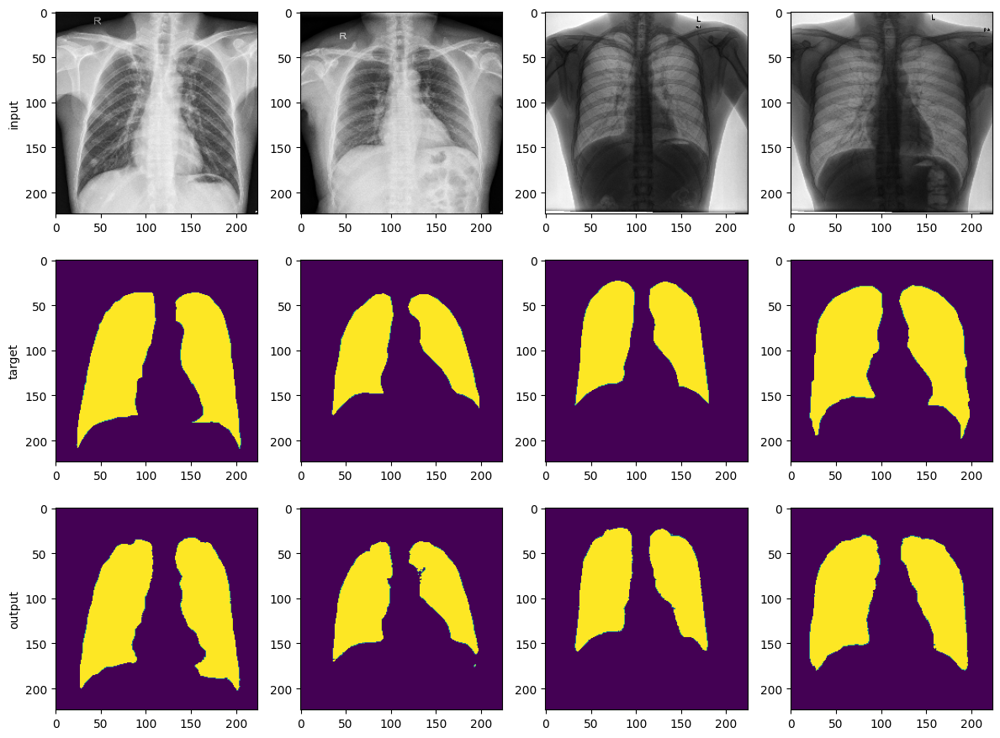

In [ ]:
ncols, nrows = 4, 3
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3*ncols, 3*nrows))
for i in range(ncols):
    axes[0,i].imshow(pred_dict['input'][i])
    axes[0,0].set_ylabel('input')

    axes[1,i].imshow(pred_dict['target'][i])
    axes[1,0].set_ylabel('target')

    axes[2,i].imshow(pred_dict['output'][i])
    axes[2,0].set_ylabel('output')

plt.tight_layout()
plt.show()

### UNET

오토인코더(autoencoder)와 같은 인코더-디코더(encoder-decoder) 기반 모델

U-Net의 기본 아이디어는 저차원 뿐만 아니라 고차원 정보도 이용하여 이미지의 특징을 추출함과 동시에 정확한 위치 파악도 가능하게 하자

인코딩 단계의 각 레이어에서 얻은 특징을 디코딩 단계의 각 레이어에 합치는(concatenation) 방법을 사용

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdlXX6i%2FbtrNT9t903d%2FK0mfIPHAHmNgZsjBlnCJpk%2Fimg.png)

구조가 U자 모양이어서 UNET!

인코더와 디코더를 연결하는 부분을 브릿지(bridge)라고 부른다





일단 인코더 부분을 확대해서 보자

![](https://i.imgur.com/uZ1NptA.png)


ConvBlock

그림에서 파란색 박스는 아래와 같이 구성되어 있다.

![](https://i.imgur.com/GXZsC0I.png)


```python
""" Conv Block """
class ConvBlock(tf.keras.layers.Layer):
    def __init__(self, n_filters):
        super().__init__()

        self.conv1 = Conv2D(n_filters, 3, padding='same')
        self.conv2 = Conv2D(n_filters, 3, padding='same')

        self.bn1 = BatchNormalization()
        self.bn2 = BatchNormalization()

        self.activation = Activation('relu')

    def call(self, inputs):
        x = self.conv1(inputs)
        x = self.bn1(x)
        x = self.activation(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.activation(x)

        return x
```

Encoder Block

보라색 박스에서 나오는 출력이 2개인데 한 개는 U-Net의 디코더로 복사하기 위한 연결선과 다운 샘플링하여 인코더의 다음 단계로 보내는 연결선이 있다.

![](https://i.imgur.com/45rY6LE.png)



```python
""" Encoder Block """
class EncoderBlock(tf.keras.layers.Layer):
    def __init__(self, n_filters):
        super().__init__()

        self.conv_blk = ConvBlock(n_filters)
        self.pool = MaxPooling2D((2,2))

    def call(self, inputs):
        x = self.conv_blk(inputs)
        p = self.pool(x)
        return x, p
```

다음 디코더 부분을 확대해서 보자

![](https://i.imgur.com/JD2SM8X.png)

Decoder Block

이전 레이어 출력과 인코더 출력을 합쳐서 저차원 이미지 정보 뿐아니라 고차원 정보도 이용할 수 있다



```python
""" Decoder Block """
class DecoderBlock(tf.keras.layers.Layer):
    def __init__(self, n_filters):
        super(DecoderBlock, self).__init__()

        self.up = Conv2DTranspose(n_filters, (2,2), strides=2, padding='same')
        self.conv_blk = ConvBlock(n_filters)

    def call(self, inputs, skip):
        x = self.up(inputs)
        x = Concatenate()([x, skip])
        x = self.conv_blk(x)

        return x
```

이를 합친 UNET 코드



```python
""" U-Net Model """
class UNET(tf.keras.Model):
    def __init__(self, n_classes):
        super(UNET, self).__init__()

        # Encoder
        self.e1 = EncoderBlock(64)
        self.e2 = EncoderBlock(128)
        self.e3 = EncoderBlock(256)
        self.e4 = EncoderBlock(512)

        # Bridge
        self.b = ConvBlock(1024)

        # Decoder
        self.d1 = DecoderBlock(512)
        self.d2 = DecoderBlock(256)
        self.d3 = DecoderBlock(128)
        self.d4 = DecoderBlock(64)

        # Outputs
        if n_classes == 1:
            activation = 'sigmoid'
        else:
            activation = 'softmax'

        self.outputs = Conv2D(n_classes, 1, padding='same', activation=activation)

    def call(self, inputs):
        s1, p1 = self.e1(inputs)
        s2, p2 = self.e2(p1)
        s3, p3 = self.e3(p2)
        s4, p4 = self.e4(p3)

        b = self.b(p4)

        d1 = self.d1(b, s4)
        d2 = self.d2(d1, s3)
        d3 = self.d3(d2, s2)
        d4 = self.d4(d3, s1)

        outputs = self.outputs(d4)

        return outputs
```




### 동일 데이터로 UNET 구현

In [ ]:
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()

        def CBR2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=True):
            layers = []
            layers += [nn.Conv2d(in_channels=in_channels, out_channels=out_channels,
                                 kernel_size=kernel_size, stride=stride, padding=padding,
                                 bias=bias)]
            layers += [nn.BatchNorm2d(num_features=out_channels)]
            layers += [nn.ReLU()]

            cbr = nn.Sequential(*layers)

            return cbr

        # Contracting path
        self.enc1_1 = CBR2d(in_channels=3, out_channels=64)
        self.enc1_2 = CBR2d(in_channels=64, out_channels=64)
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        self.enc2_1 = CBR2d(in_channels=64, out_channels=128)
        self.enc2_2 = CBR2d(in_channels=128, out_channels=128)
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        self.enc3_1 = CBR2d(in_channels=128, out_channels=256)
        self.enc3_2 = CBR2d(in_channels=256, out_channels=256)
        self.pool3 = nn.MaxPool2d(kernel_size=2)

        self.enc4_1 = CBR2d(in_channels=256, out_channels=512)
        self.enc4_2 = CBR2d(in_channels=512, out_channels=512)
        self.pool4 = nn.MaxPool2d(kernel_size=2)

        self.enc5_1 = CBR2d(in_channels=512, out_channels=1024)

        # Expansive path
        self.dec5_1 = CBR2d(in_channels=1024, out_channels=512)

        self.unpool4 = nn.ConvTranspose2d(in_channels=512, out_channels=512,
                                          kernel_size=2, stride=2, padding=0, bias=True)
        self.dec4_2 = CBR2d(in_channels=2 * 512, out_channels=512)
        self.dec4_1 = CBR2d(in_channels=512, out_channels=256)

        self.unpool3 = nn.ConvTranspose2d(in_channels=256, out_channels=256,
                                          kernel_size=2, stride=2, padding=0, bias=True)
        self.dec3_2 = CBR2d(in_channels=2 * 256, out_channels=256)
        self.dec3_1 = CBR2d(in_channels=256, out_channels=128)

        self.unpool2 = nn.ConvTranspose2d(in_channels=128, out_channels=128,
                                          kernel_size=2, stride=2, padding=0, bias=True)
        self.dec2_2 = CBR2d(in_channels=2 * 128, out_channels=128)
        self.dec2_1 = CBR2d(in_channels=128, out_channels=64)

        self.unpool1 = nn.ConvTranspose2d(in_channels=64, out_channels=64,
                                          kernel_size=2, stride=2, padding=0, bias=True)
        self.dec1_2 = CBR2d(in_channels=2 * 64, out_channels=64)
        self.dec1_1 = CBR2d(in_channels=64, out_channels=64)

        self.fc = nn.Conv2d(in_channels=64, out_channels=2, kernel_size=1, stride=1, padding=0, bias=True)

    def forward(self, x):
        enc1_1 = self.enc1_1(x)
        enc1_2 = self.enc1_2(enc1_1)
        pool1 = self.pool1(enc1_2)

        enc2_1 = self.enc2_1(pool1)
        enc2_2 = self.enc2_2(enc2_1)
        pool2 = self.pool2(enc2_2)

        enc3_1 = self.enc3_1(pool2)
        enc3_2 = self.enc3_2(enc3_1)
        pool3 = self.pool3(enc3_2)

        enc4_1 = self.enc4_1(pool3)
        enc4_2 = self.enc4_2(enc4_1)
        pool4 = self.pool4(enc4_2)

        enc5_1 = self.enc5_1(pool4)

        dec5_1 = self.dec5_1(enc5_1)

        unpool4 = self.unpool4(dec5_1)
        cat4 = torch.cat((unpool4, enc4_2), dim=1)
        dec4_2 = self.dec4_2(cat4)
        dec4_1 = self.dec4_1(dec4_2)

        unpool3 = self.unpool3(dec4_1)
        cat3 = torch.cat((unpool3, enc3_2), dim=1)
        dec3_2 = self.dec3_2(cat3)
        dec3_1 = self.dec3_1(dec3_2)

        unpool2 = self.unpool2(dec3_1)
        cat2 = torch.cat((unpool2, enc2_2), dim=1)
        dec2_2 = self.dec2_2(cat2)
        dec2_1 = self.dec2_1(dec2_2)

        unpool1 = self.unpool1(dec2_1)
        cat1 = torch.cat((unpool1, enc1_2), dim=1)
        dec1_2 = self.dec1_2(cat1)
        dec1_1 = self.dec1_1(dec1_2)

        x = self.fc(dec1_1)

        return x

model = UNet()
model_summary(model, (3,224,224), device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 224, 224]           1,792
       BatchNorm2d-2         [-1, 64, 224, 224]             128
              ReLU-3         [-1, 64, 224, 224]               0
            Conv2d-4         [-1, 64, 224, 224]          36,928
       BatchNorm2d-5         [-1, 64, 224, 224]             128
              ReLU-6         [-1, 64, 224, 224]               0
         MaxPool2d-7         [-1, 64, 112, 112]               0
            Conv2d-8        [-1, 128, 112, 112]          73,856
       BatchNorm2d-9        [-1, 128, 112, 112]             256
             ReLU-10        [-1, 128, 112, 112]               0
           Conv2d-11        [-1, 128, 112, 112]         147,584
      BatchNorm2d-12        [-1, 128, 112, 112]             256
             ReLU-13        [-1, 128, 112, 112]               0
        MaxPool2d-14          [-1, 128,

In [ ]:
model = model.to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=2e-4)

CE_LOSS = torch.nn.CrossEntropyLoss()

In [ ]:
losses = {'train':[], 'val':[]}

for epoch in range(1, EPOCHS+1):
    train_loss = train(model, train_loader, optimizer)
    val_loss = evaluate(model, val_loader)

    losses['train'].append(train_loss)
    losses['val'].append(val_loss)

    print(f'[{epoch}] Train Loss: {train_loss:.6f}')
    print(f'[{epoch}] Test Loss: {val_loss:.6f}')

Training complete in 5m 9s
[1] Train Loss: 0.223886
[1] Test Loss: 0.249989
Training complete in 5m 24s
[2] Train Loss: 0.124668
[2] Test Loss: 0.139084
Training complete in 5m 52s
[3] Train Loss: 0.107184
[3] Test Loss: 0.289249
Training complete in 5m 31s
[4] Train Loss: 0.097199
[4] Test Loss: 0.134633
Training complete in 5m 54s
[5] Train Loss: 0.088236
[5] Test Loss: 0.319690
Training complete in 5m 42s
[6] Train Loss: 0.092181
[6] Test Loss: 0.390510
Training complete in 5m 53s
[7] Train Loss: 0.085520
[7] Test Loss: 0.201744
Training complete in 5m 14s
[8] Train Loss: 0.099881
[8] Test Loss: 0.526136
Training complete in 5m 43s
[9] Train Loss: 0.101215
[9] Test Loss: 0.310458
Training complete in 5m 8s
[10] Train Loss: 0.074991
[10] Test Loss: 0.102986


In [ ]:
test_ds = MyDataLoader(X_test, y_test,
                      transforms_x=val_x_transforms, transforms_y=val_y_transforms)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=0)
len_test = len(test_loader)

pred_dict = {'input':[], 'target':[], 'output':[]}

model.to('cpu')
model.eval()
with torch.no_grad():
    for i, (data, target) in enumerate(test_loader):
        data, target = data.to('cpu'), target.to('cpu')
        output = model(data).detach().cpu()
        output = torch.argmax(output, dim=1, keepdim=True)

        data_ = data[0].permute(1,2,0)
        target_ = target[0].permute(1,2,0)[:,:,-1]
        output_ = output[0].permute(1,2,0)[:,:,-1]

        pred_dict['input'].append(data_)
        pred_dict['target'].append(target_)
        pred_dict['output'].append(output_)

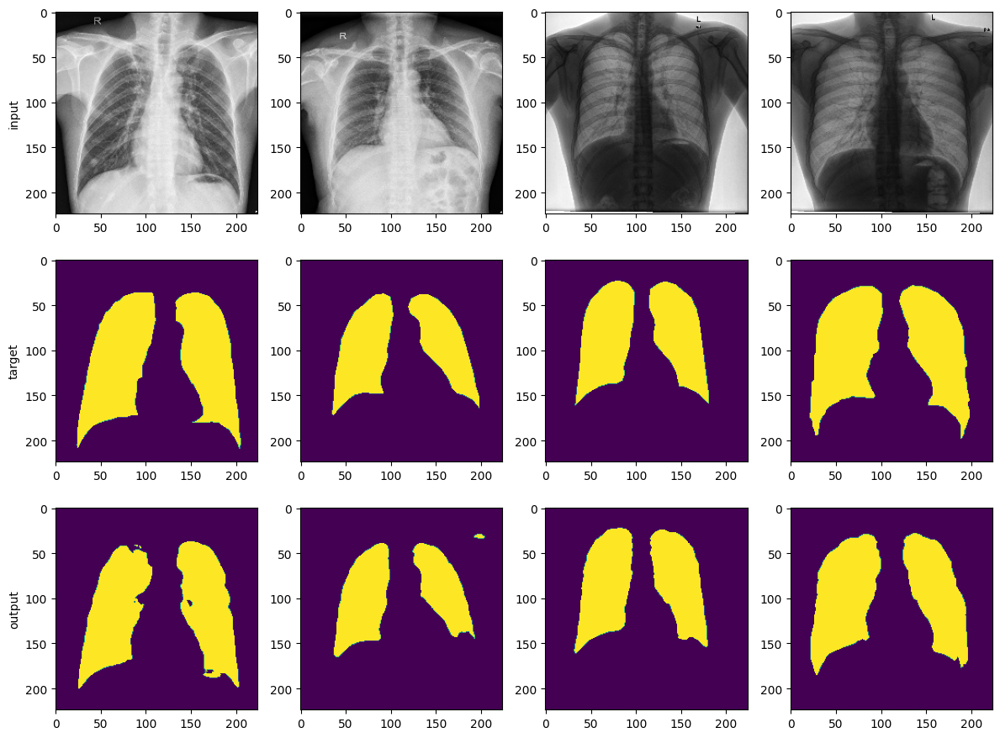

In [ ]:
ncols, nrows = 4, 3
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3*ncols, 3*nrows))
for i in range(ncols):
    axes[0,i].imshow(pred_dict['input'][i])
    axes[0,0].set_ylabel('input')

    axes[1,i].imshow(pred_dict['target'][i])
    axes[1,0].set_ylabel('target')

    axes[2,i].imshow(pred_dict['output'][i])
    axes[2,0].set_ylabel('output')

plt.tight_layout()
plt.show()

## Mask R-CNN → SAM

### Mask R-CNN

Faster R-CNN에 mask를 생성하는 브랜치를 병렬적으로 추가한 모델

기존 task에 일반적으로 잘 적용할 수 있는 장점

3가지의 Branch를 가진다

* Classification Branch : Faster R-CNN에서 얻은 RoI(Region of Interest)에 대해 객체의 class 예측

* Bbox Regression Branch : bounding box 예측

* Mask Branch : segmentation mask 예측

![](https://miro.medium.com/v2/resize:fit:1100/format:webp/0*xqeT1wT1TdwU7UeK.png)

또다른 특징! RoI Pooling 대신 ROI Align기법을 사용

class를 먼저 예측하고 그 class안에서 mask를 생성한다

**Faster R-CNN과의 차이**

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F0la9l%2FbtqW8HCsFxL%2FVk4TtWhixEt4gzdTo0srsk%2Fimg.png)

위의 구조는 Faster R-CNN

backbone network를 통해 얻은 feature map을 RPN(Region Proposal Network)에 입력하여 RoIs(Region of Interests)를 얻는다

RoI pooling을 통해 고정된 크기의 feature map을 얻고 이를 fc layer에 입력한 후 classification branch와 bbox regression branch에 입력하여 class label과 bbox offset이라는 두 가지 결과를 예측

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fcx1zeb%2FbtqWX5EbBpp%2FSDi2o1RDnpCCs2ckVpA8d0%2Fimg.png)

Mask R-CNN은 두 branch와 평행(pararell)으로 segmentation mask를 예측하는 mask branch가 추가된 구조

**ROIAlign**

RoIPool 대신에 bilinear interpolation을 이용해서 위치정보를 담는다

![](https://miro.medium.com/v2/resize:fit:1100/format:webp/0*IG0xWQ-p72bem7NQ.png)

각 서브셀 내부에서 bilinear interpolation(양방향 보간법)을 하고 그걸 더한 값이 모여서 하나의 서브셀 값을 만든다

![](https://miro.medium.com/v2/resize:fit:1100/format:webp/0*lOR2XkJI09ArH9l4.png)

계산이 완료된 서브셀이 16개가 나오는데 이 때 각 셀에 대하여 max pooling을 통해 RoI를 구한다

![](https://miro.medium.com/v2/resize:fit:1100/format:webp/0*A28fW7E4q3eJXH39.png)




**Mask Branch**

segmentation task는 픽셀 단위로 class를 분류해야 하기 때문에 detection task보다 더 정교한 spatial layout(공간에 대한 배치 정보)를 필요로 한다

Mask Branch는 여러 개의 convolution를 사용하여 pixel-to-pixel 정보를 추출한다

각 RoI에 대해 m x m 크기의 K개 mask를 예측(K는 class 수)

각각의 RoI에 대하여 class별로 binary mask를 출력

![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fbu2jXB%2Fbtq98djIE3Q%2FwY2MQiAdgmkK6ZIZjp15OK%2Fimg.png)

**Mask R-CNN의 손실함수**

$L = L_{cls} + L_{box} + L_{mask}$

cls : 클래스 분류 loss

box : bounding box loss

mask : mask branch의 mask loss

</br>


이 때 $L_{mask}$는 각각의 RoI에 대해 $K⋅m^2$차원의 output을 출력하는데, m x m 해상도를 가진 이미지에 대해 binary mask class가 K개 있다는 의미이다.

K개의 binary mask는 픽셀당 sigmoid를 적용하고, $L_{mask}$는 average binary cross entropy loss를 적용한다

Mask R-CNN에서는 각 Class를 먼저 분류하고 그 안에서 mask를 찾기 때문에 softmax가 아닌 sigmoid를 이용하여 mask인지 아닌지 판단한다.

![](https://miro.medium.com/v2/resize:fit:1100/0*dSApi71EoP2XkuP4.gif)

### 미리 학습된 Mask R-CNN 모델을 Fine Tuning 해보자

In [ ]:
%matplotlib inline

import os
import numpy as np
import torch
from PIL import Image

In [ ]:
!wget https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip

--2023-09-13 09:23:35--  https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip
Resolving www.cis.upenn.edu (www.cis.upenn.edu)... 158.130.69.163, 2607:f470:8:64:5ea5::d
Connecting to www.cis.upenn.edu (www.cis.upenn.edu)|158.130.69.163|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 53723336 (51M) [application/zip]
Saving to: ‘PennFudanPed.zip’

PennFudanPed.zip    100%[===================>]  51.23M  20.5MB/s    in 2.5s    

2023-09-13 09:23:38 (20.5 MB/s) - ‘PennFudanPed.zip’ saved [53723336/53723336]



In [ ]:
! unzip -q /content/PennFudanPed

데이터셋 코드 정의

데이터 예
![](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image01.png)

![](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image02.png)

In [ ]:
class PennFudanDataset(torch.utils.data.Dataset):
    def __init__(self, root, transforms):
        self.root = root
        self.transforms = transforms
        # 모든 이미지 파일들을 읽고, 정렬하여
        # 이미지와 분할 마스크 정렬을 확인합니다
        self.imgs = list(sorted(os.listdir(os.path.join(root, "PNGImages"))))
        self.masks = list(sorted(os.listdir(os.path.join(root, "PedMasks"))))

    def __getitem__(self, idx):
        # 이미지와 마스크를 읽어옵니다
        img_path = os.path.join(self.root, "PNGImages", self.imgs[idx])
        mask_path = os.path.join(self.root, "PedMasks", self.masks[idx])
        img = Image.open(img_path).convert("RGB")
        # 분할 마스크는 RGB로 변환하지 않음을 유의하세요
        # 왜냐하면 각 색상은 다른 인스턴스에 해당하며, 0은 배경에 해당합니다
        mask = Image.open(mask_path)
        # numpy 배열을 PIL 이미지로 변환합니다
        mask = np.array(mask)
        # 인스턴스들은 다른 색들로 인코딩 되어 있습니다.
        obj_ids = np.unique(mask)
        # 첫번째 id 는 배경이라 제거합니다
        obj_ids = obj_ids[1:]

        # 컬러 인코딩된 마스크를 바이너리 마스크 세트로 나눕니다
        masks = mask == obj_ids[:, None, None]

        # 각 마스크의 바운딩 박스 좌표를 얻습니다
        num_objs = len(obj_ids)
        boxes = []
        for i in range(num_objs):
            pos = np.where(masks[i])
            xmin = np.min(pos[1])
            xmax = np.max(pos[1])
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])
            boxes.append([xmin, ymin, xmax, ymax])

        # 모든 것을 torch.Tensor 타입으로 변환합니다
        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        # 객체 종류는 한 종류만 존재합니다(역자주: 예제에서는 사람만이 대상입니다)
        labels = torch.ones((num_objs,), dtype=torch.int64)
        masks = torch.as_tensor(masks, dtype=torch.uint8)

        image_id = torch.tensor([idx])
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
        # 모든 인스턴스는 군중(crowd) 상태가 아님을 가정합니다
        iscrowd = torch.zeros((num_objs,), dtype=torch.int64)

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["masks"] = masks
        target["image_id"] = image_id
        target["area"] = area
        target["iscrowd"] = iscrowd

        if self.transforms is not None:
            img, target = self.transforms(img, target)

        return img, target

    def __len__(self):
        return len(self.imgs)

COCO에 대해 미리 학습된 모델에서 시작하여 특정 클래스를 위해 미세 조정을 해보자

In [ ]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor


def get_model_instance_segmentation(num_classes):
    # COCO 에서 미리 학습된 인스턴스 분할 모델을 읽어옵니다
    model = torchvision.models.detection.maskrcnn_resnet50_fpn(weights="DEFAULT")

    # 분류를 위한 입력 특징 차원을 얻습니다
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # 미리 학습된 헤더를 새로운 것으로 바꿉니다
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # 마스크 분류기를 위한 입력 특징들의 차원을 얻습니다
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    # 마스크 예측기를 새로운 것으로 바꿉니다
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask,
                                                       hidden_layer,
                                                       num_classes)

    return model

데이터 증강 / 변환을 위한 도움 함수 정의

In [ ]:
import transforms as T

def get_transform(train):
    transforms = []
    transforms.append(T.PILToTensor())
    transforms.append(T.ConvertImageDtype(torch.float))
    if train:
        # (역자주: 학습시 50% 확률로 학습 영상을 좌우 반전 변환합니다)
        transforms.append(T.RandomHorizontalFlip(0.5))
    return T.Compose(transforms)

학습과 검즘을 수행하는 메인 함수 작성

In [ ]:
from engine import train_one_epoch, evaluate
import utils


def main():
    # 학습을 GPU로 진행하되 GPU가 가용하지 않으면 CPU로 합니다
    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

    # 우리 데이터셋은 두 개의 클래스만 가집니다 - 배경과 사람
    num_classes = 2
    # 데이터셋과 정의된 변환들을 사용합니다
    dataset = PennFudanDataset('PennFudanPed', get_transform(train=True))
    dataset_test = PennFudanDataset('PennFudanPed', get_transform(train=False))

    # 데이터셋을 학습용과 테스트용으로 나눕니다(역자주: 여기서는 전체의 50개를 테스트에, 나머지를 학습에 사용합니다)
    indices = torch.randperm(len(dataset)).tolist()
    dataset = torch.utils.data.Subset(dataset, indices[:-50])
    dataset_test = torch.utils.data.Subset(dataset_test, indices[-50:])

    # 데이터 로더를 학습용과 검증용으로 정의합니다
    data_loader = torch.utils.data.DataLoader(
        dataset, batch_size=2, shuffle=True, num_workers=4,
        collate_fn=utils.collate_fn)

    data_loader_test = torch.utils.data.DataLoader(
        dataset_test, batch_size=1, shuffle=False, num_workers=4,
        collate_fn=utils.collate_fn)

    # 도움 함수를 이용해 모델을 가져옵니다
    model = get_model_instance_segmentation(num_classes)

    # 모델을 GPU나 CPU로 옮깁니다
    model.to(device)

    # 옵티마이저(Optimizer)를 만듭니다
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=0.005,
                                momentum=0.9, weight_decay=0.0005)
    # 학습률 스케쥴러를 만듭니다
    lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                                   step_size=3,
                                                   gamma=0.1)

    # 10 에포크만큼 학습해봅시다
    num_epochs = 10

    for epoch in range(num_epochs):
        # 1 에포크동안 학습하고, 10회 마다 출력합니다
        train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq=10)
        # 학습률을 업데이트 합니다
        lr_scheduler.step()
        # 테스트 데이터셋에서 평가를 합니다
        evaluate(model, data_loader_test, device=device)

    print("That's it!")

In [ ]:
import matplotlib.pyplot as plt

from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks


image = read_image("../_static/img/tv_tutorial/tv_image05.png")
eval_transform = get_transform(train=False)

model.eval()
with torch.no_grad():
    x = eval_transform(image)
    # convert RGBA -> RGB and move to device
    x = x[:3, ...].to(device)
    predictions = model([x, ])
    pred = predictions[0]


image = (255.0 * (image - image.min()) / (image.max() - image.min())).to(torch.uint8)
image = image[:3, ...]
pred_labels = [f"pedestrian: {score:.3f}" for label, score in zip(pred["labels"], pred["scores"])]
pred_boxes = pred["boxes"].long()
output_image = draw_bounding_boxes(image, pred_boxes, pred_labels, colors="red")

masks = (pred["masks"] > 0.7).squeeze(1)
output_image = draw_segmentation_masks(output_image, masks, alpha=0.5, colors="blue")


plt.figure(figsize=(12, 12))
plt.imshow(output_image.permute(1, 2, 0))

예측 결과 확인

![](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image05.png)

![](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image06.png)
![](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image07.png)

### SAM (Segment Anything Model)

Image Segmentation에 대한 Foundation Model을 만드는 것을 목표로 한 모델

> Foundation Model?
>
> 분야를 막론하고 거대한 데이터셋으로 Pre-training 시킨 거대한 모델
>
> 한마디로 방대한 이해도를 갖춘 모델

![](https://global-uploads.webflow.com/6434d6a6071644318551fd72/6486a21a7a938f2d98e619f9_AnyConv.com__%E1%84%83%E1%85%A1%E1%84%8B%E1%85%AE%E1%86%AB%E1%84%85%E1%85%A9%E1%84%83%E1%85%B3.webp)

**Task**

* zero-shot 학습

> zero shot
>
> 모델이 학습 과정에서 배우지 않은 작업을 수행하는 것

* Prompt 기반의 모델 : 점(point), 박스(box), 텍스트(text)를 입력으로 받음

**Model**

* (Powerful) Image encoder

    ViT 기반 모델로 추론 시 긴 시간이 소요되지만 강력한 encoder를 가짐

* Prompt encoder

* Mask decoder

    Image encoder에 비해 Prompt encoder와 Mask decoder는 아주 가벼워서 웹에서도 50ms 이내로 동작

![](https://global-uploads.webflow.com/6434d6a6071644318551fd72/646eceb5c1ea99360752721f_AnyConv.com__730f883d-e952-4b44-bd53-1ce0fd5a0a5c.webp)


**Data**

거대한 데이터 셋이 필요함

Segmentation에 필요한 마스크를 구하기 위해 Data Engine을 만듬

1. Assisted-manual: 작업자가 점을 찍으면 SAM 모델이 어느정도 마스크를 만들어 레이블링을 도와줌
2. Semi-automatic: 특정 object 집합에 대해 SAM이 알아서 마스크를 만들면 동시에 작업자가 다른 object에 대해 마스크를 만듬
3. Fully automatic: 이미지에 grid point를 찍어서 모든걸 알아서 masking하도록 만듬

![](https://global-uploads.webflow.com/6434d6a6071644318551fd72/6486a3676d4747bb486a7ba1_AnyConv.com__%E1%84%89%E1%85%B3%E1%84%8F%E1%85%B3%E1%84%85%E1%85%B5%E1%86%AB%E1%84%89%E1%85%A3%E1%86%BA%202023-06-12%20%E1%84%8B%E1%85%A9%E1%84%8C%E1%85%A5%E1%86%AB%2011.37.53.webp)

=> SA-1B 데이터셋


Segment Anything 구조

**Image Encoder**

pre-trained Vision Transfomer(ViT)의 하나인 Masked Autoencoder(MAE)를 사용

![](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*l8zPV1sSDmEPbwHTDh5Rzw.png)

**Prompt Encoder**

prompt를 sparse(points, boxes, text)와 dense(mask)로 나누어 정의

**Mask decoder**

transformer decoder block과 dynamic mask prediction head를 사용

![](https://miro.medium.com/v2/resize:fit:720/format:webp/1*sN8cexlVUikfA0oLR-f5cA.png)


데모 링크: https://segment-anything.com/

논문에서는 prompt를 text, mask, bbox, point가 가능하다고 했지만 데모 및 공개 코드에는 bbox와 point로만 가능하게 나와있음